In [1]:
import glob
import os
import pickle
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


# ============================================================
# File paths
# ============================================================

ROOT = os.path.abspath("../../../../results")

# 20 steps
files_3t15t_20_steps = (
    f"{ROOT}/latent_tta_20_steps/"
    "pmri_threet-to-onepointfivet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_15t3t_20_steps = (
    f"{ROOT}/latent_tta_20_steps/"
    "pmri_onepointfivet-to-threet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_promise12_20_steps = (
    f"{ROOT}/latent_tta_20_steps/"
    "pmri_promise12_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

# 100 steps
files_3t15t_100_steps = (
    f"{ROOT}/latent_tta_100_steps/"
    "pmri_threet-to-onepointfivet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_15t3t_100_steps = (
    f"{ROOT}/latent_tta_100_steps/"
    "pmri_onepointfivet-to-threet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_promise12_100_steps = (
    f"{ROOT}/latent_tta_100_steps/"
    "pmri_promise12_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

# 1000 steps
files_3t15t_1000_steps = (
    f"{ROOT}/latent_tta_1000_steps/"
    "pmri_threet-to-onepointfivet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_15t3t_1000_steps = (
    f"{ROOT}/latent_tta_1000_steps/"
    "pmri_onepointfivet-to-threet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_promise12_1000_steps = (
    f"{ROOT}/latent_tta_1000_steps/"
    "pmri_promise12_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

In [2]:
def load_results_per_case(base_path, evaluation_key):
    dice_before = []
    dice_after = []
    delta_dice = []

    for x in range(5):
        matches = glob.glob(
            f"{base_path}{x}*/latent_tta.pkl"
        )
        path = matches[0]

        with open(path, "rb") as f:
            data = pickle.load(f)

        evaluation = data["evaluation"][evaluation_key]

        dice_before_match = evaluation["dice_before"]
        dice_after_match = evaluation["dice_after"]

        delta_dice_match = dice_after_match - dice_before_match
        print(f"Max delta dice: {torch.max(delta_dice_match):.2f}")
        print(f" Dice Before Match: {dice_before_match[torch.argmax(delta_dice_match)]:.2f}")
        print(f" Dice After Match: {dice_after_match[torch.argmax(delta_dice_match)]:.2f}")
        print()
        print(f"Min delta dice: {torch.min(delta_dice_match):.2f}")
        print(f" Dice Before Match: {dice_before_match[torch.argmin(delta_dice_match)]:.2f}")
        print(f" Dice After Match: {dice_after_match[torch.argmin(delta_dice_match)]:.2f}")
        print(delta_dice_match)
        print("\n===================\n")

load_results_per_case(files_promise12_1000_steps, "promise12_test")

Max delta dice: 0.80
 Dice Before Match: 0.00
 Dice After Match: 0.80

Min delta dice: -0.21
 Dice Before Match: 0.76
 Dice After Match: 0.54
tensor([ 0.0990,  0.0222,  0.1972,  ..., -0.0071, -0.0608, -0.1050])


Max delta dice: 0.64
 Dice Before Match: 0.18
 Dice After Match: 0.82

Min delta dice: -0.20
 Dice Before Match: 0.90
 Dice After Match: 0.71
tensor([ 0.0649, -0.0469,  0.0467,  ..., -0.0448, -0.0726, -0.1463])


Max delta dice: 0.75
 Dice Before Match: 0.00
 Dice After Match: 0.76

Min delta dice: -0.23
 Dice Before Match: 0.68
 Dice After Match: 0.45
tensor([ 0.0318, -0.0126,  0.2624,  ..., -0.0417,  0.0017, -0.1077])


Max delta dice: 0.75
 Dice Before Match: 0.12
 Dice After Match: 0.87

Min delta dice: -0.24
 Dice Before Match: 0.68
 Dice After Match: 0.44
tensor([ 0.1360, -0.0466,  0.2847,  ..., -0.0832, -0.2107, -0.1685])


Max delta dice: 0.79
 Dice Before Match: 0.00
 Dice After Match: 0.79

Min delta dice: -0.64
 Dice Before Match: 0.88
 Dice After Match: 0.24
tensor

---

# Per-case analysis of latent TTA

Everything below works on the **per-case** tensors in `evaluation[<domain>_test]`, across all
3 domains × 3 step budgets × 5 score predictors (45 runs). One entry of `dice_before` /
`dice_after` / `dice_per_step` is one evaluated case.

Two facts that make the per-case comparisons below valid, both verified in the loader:

* `dice_before` is **bit-identical** across every budget and every predictor within a domain —
  the baseline U-Net is fixed, so case *i* is the same case in every run and can be compared by index.
* `metadata.tta.max_steps` matches the folder name for all 45 runs, so `latent_tta_1000_steps`
  really contains 1000-step ascents. The 20- and 100-step runs are *independent* runs, not
  prefixes of the 1000-step ones — the GPU is non-deterministic, so a given case can end up
  somewhere else (rank correlation between reruns is ≈0.98, but individual cases move).

The sections answer: **who gets helped, who gets hurt, when does it flip, and how much would a
stopping rule buy.** Section 7 repeats the same analyses for the four 100-step variants
(pre-/post-norm predictor × with/without logit adapter).

In [3]:
import glob
import os
import pickle
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# ============================================================
# Loading
# ============================================================

ROOT = os.path.abspath("../../../../results")
PRED_TAG = "dice_predictor-adversarial-location-concentration_beta-cleanHalf_"

DOMAINS = {
    "threet-to-onepointfivet": "3T→1.5T",
    "promise12": "PROMISE12",
    "onepointfivet-to-threet": "1.5T→3T",
}
PREDICTORS = range(5)
ORDER = list(DOMAINS.values())


@dataclass(frozen=True)
class Run:
    """A results folder, plus what the metadata of every pickle in it has to say."""
    folder: str
    steps: int                   # tta.max_steps
    hook: str | None = None      # model.hook_placement of the score predictor: "pre" / "post" norm
    logits: bool | None = None   # tta.adapt_logits


RUNS = {
    # sections 1–6: step-budget study, latent sites only
    "20 steps": Run("latent_tta_20_steps", 20),
    "100 steps": Run("latent_tta_100_steps", 100),
    "1000 steps": Run("latent_tta_1000_steps", 1000),
    # section 7: pre-/post-norm predictor × with/without logit affine, 100 steps each
    "post-norm": Run("latent_tta_postnorm", 100, hook="post", logits=False),
    "post-norm + logits": Run("latent_tta_postnorm_logits", 100, hook="post", logits=True),
    "pre-norm": Run("latent_tta_prenorm", 100, hook="pre", logits=False),
    "pre-norm + logits": Run("latent_tta_prenorm_logits", 100, hook="pre", logits=True),
}
BUDGETS = [20, 100, 1000]
VARIANT_NAMES = ["post-norm", "post-norm + logits", "pre-norm", "pre-norm + logits"]

# the only per-case tensors the analysis reads; examples, traces and threshold grids are dropped
KEEP = ("dice_before", "dice_after", "best_dice", "best_step", "mu_before", "mu_after", "dice_per_step")


def resolve(run):
    """Run name; an int step budget is shorthand for "<budget> steps"."""
    return f"{run} steps" if isinstance(run, (int, np.integer)) else run


def run_path(domain, run, predictor):
    folder = RUNS[resolve(run)].folder
    hits = sorted(glob.glob(f"{ROOT}/{folder}/pmri_{domain}_{PRED_TAG}{predictor}_*/latent_tta.pkl"))
    if len(hits) != 1:
        raise FileNotFoundError(f"{len(hits)} matches for {domain}/{folder}/p{predictor}")
    return hits[0]


def missing_runs(run):
    """(domain, predictor) pairs of `run` that do not have exactly one pickle on disk."""
    missing = []
    for domain in DOMAINS:
        for p in PREDICTORS:
            try:
                run_path(domain, run, p)
            except FileNotFoundError:
                missing.append((domain, p))
    return missing


_CACHE = {}


def load_run(domain, run, predictor, split="test"):
    """(metadata, evaluation dict for `split`), cached.

    Raises if the pickle's own metadata disagrees with the folder it sits in -- the
    wrapper scripts override tta.max_steps, the predictor checkpoint and adapt_logits
    from shell variables, so a mislabelled folder is a real failure mode here.
    """
    name = resolve(run)
    key = (domain, name, predictor)
    if key not in _CACHE:
        with open(run_path(domain, name, predictor), "rb") as fh:
            blob = pickle.load(fh)
        meta, spec = blob["metadata"], RUNS[name]
        checks = [("tta.max_steps", meta["tta"]["max_steps"], spec.steps),
                  ("model.hook_placement", meta["model"].get("hook_placement"), spec.hook),
                  ("tta.adapt_logits", meta["tta"].get("adapt_logits"), spec.logits)]
        for field, ran, expected in checks:
            if expected is not None and ran != expected:
                raise ValueError(f"{domain}/p{predictor} in {spec.folder}: {field}={ran}, expected {expected}")
        _CACHE[key] = (meta, {s: {k: blob["evaluation"][f"{domain}_{s}"][k] for k in KEEP}
                              for s in ("val", "test")})
    meta, evaluation = _CACHE[key]
    return meta, evaluation[split]


def curve(domain, run, predictor):
    """(n_cases, steps + 1) Dice trajectory, column t = Dice after t ascent steps."""
    return load_run(domain, run, predictor)[1]["dice_per_step"].float().numpy()


def per_case_frame(runs):
    """One row per (domain, run, predictor, case)."""
    names = [resolve(r) for r in runs]
    frames = []
    for domain, label in DOMAINS.items():
        for name in names:
            for p in PREDICTORS:
                ev = load_run(domain, name, p)[1]
                num = lambda k: ev[k].float().numpy()
                frames.append(pd.DataFrame({
                    "domain": label,
                    "domain_key": domain,
                    "run": name,
                    "budget": RUNS[name].steps,
                    "predictor": p,
                    "case": np.arange(len(ev["dice_before"])),
                    "dice_before": num("dice_before"),
                    "dice_after": num("dice_after"),
                    "best_dice": num("best_dice"),
                    "best_step": ev["best_step"].numpy(),
                    "mu_before": num("mu_before"),
                    "mu_after": num("mu_after"),
                }))
    df = pd.concat(frames, ignore_index=True)
    df["domain"] = pd.Categorical(df.domain, ORDER, ordered=True)
    df["run"] = pd.Categorical(df.run, names, ordered=True)
    df["delta_dice"] = df.dice_after - df.dice_before        # what you actually get
    df["oracle_delta"] = df.best_dice - df.dice_before  # perfect per-case early stop
    df["regret"] = df.best_dice - df.dice_after         # cost of running to the budget
    return df


def check_case_alignment(runs):
    """dice_before must be identical across the given runs and predictors, else index-wise
    per-case comparison is meaningless."""
    names = [resolve(r) for r in runs]
    for domain in DOMAINS:
        ref = load_run(domain, names[0], 0)[1]["dice_before"].numpy()
        for name in names:
            for p in PREDICTORS:
                other = load_run(domain, name, p)[1]["dice_before"].numpy()
                assert np.array_equal(ref, other), f"case order differs: {domain}/{name}/p{p}"
    print(f"case alignment OK — dice_before identical across all "
          f"{len(names) * len(PREDICTORS)} runs per domain")


df = per_case_frame(BUDGETS)
check_case_alignment(BUDGETS)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

print(df.groupby(["domain", "budget"], observed=True).size().unstack())
df.head()

case alignment OK — dice_before identical across all 15 runs per domain
budget     20    100   1000
domain                     
3T→1.5T    2405  2405  2405
PROMISE12  6240  6240  6240
1.5T→3T    5605  5605  5605


,domain,domain_key,run,budget,predictor,case,dice_before,dice_after,best_dice,best_step,mu_before,mu_after,delta_dice,oracle_delta,regret
0,3T→1.5T,threet-to-onepointfivet,20 steps,20,0,0,0.580722,0.555916,0.580722,0,0.767949,0.805727,-0.024806,0.000000,0.024806
1,3T→1.5T,threet-to-onepointfivet,20 steps,20,0,1,0.509409,0.571064,0.571064,20,0.702343,0.747805,0.061655,0.061655,0.000000
2,3T→1.5T,threet-to-onepointfivet,20 steps,20,0,2,0.858955,0.804072,0.858955,0,0.847342,0.900555,-0.054883,0.000000,0.054883
3,3T→1.5T,threet-to-onepointfivet,20 steps,20,0,3,0.927801,0.903846,0.927801,0,0.936365,0.945157,-0.023955,0.000000,0.023955
4,3T→1.5T,threet-to-onepointfivet,20 steps,20,0,4,0.931232,0.932613,0.935686,12,0.913103,0.937351,0.001381,0.004454,0.003073


## 1 · Risk and reward, per budget

`mean Δ` alone hides what adaptation does, because gains and losses land on different cases.
Splitting Δ into its positive and negative parts gives a reward/risk view:

* **reward** = mean of `max(Δ, 0)` — Dice gained, averaged over *all* cases
* **risk**   = mean of `−min(Δ, 0)` — Dice destroyed, averaged over *all* cases
* **broke <0.5** — cases that were usable (≥0.5) and were pushed below 0.5. This is the number
  that matters if the output is going anywhere near a clinician.

In [4]:
EPS = 1e-3  # Dice moves below this are numerical noise, not adaptation


def risk_reward(frame, by="budget", eps=EPS):
    def agg(g):
        d = g.delta_dice.values
        gain, harm = np.clip(d, 0, None).mean(), -np.clip(d, None, 0).mean()
        return pd.Series({
            "cases": len(d) // len(PREDICTORS),
            "mean Δ": d.mean(),
            "median Δ": np.median(d),
            "helped %": 100 * (d > eps).mean(),
            "harmed %": 100 * (d < -eps).mean(),
            "reward": gain,
            "risk": harm,
            "reward/risk": gain / max(harm, 1e-9),
            "p01 Δ": np.percentile(d, 1),
            "p99 Δ": np.percentile(d, 99),
            "worst Δ": d.min(),
            "best Δ": d.max(),
            "broke <0.5 %": 100 * ((g.dice_before >= 0.5) & (g.dice_after < 0.5)).mean(),
            "fixed <0.5 %": 100 * ((g.dice_before < 0.5) & (g.dice_after >= 0.5)).mean(),
        })

    return frame.groupby(["domain", by], observed=True).apply(agg, include_groups=False)


risk_reward(df).round(3)

cases  mean Δ  median Δ  helped %  harmed %  reward   risk  reward/risk  p01 Δ  p99 Δ  worst Δ  best Δ  broke <0.5 %  fixed <0.5 %
domain    budget                                                                                                                                     
3T→1.5T   20       481.0   0.064     0.016    70.478    20.457   0.069  0.004       15.640 -0.072  0.655   -0.365   0.895         0.748         7.651
          100      481.0   0.076     0.018    62.287    31.518   0.093  0.017        5.452 -0.192  0.787   -0.389   0.955         1.414         9.854
          1000     481.0  -0.106    -0.104    25.572    70.395   0.044  0.149        0.291 -0.566  0.631   -0.688   0.948        17.547         4.740
PROMISE12 20      1248.0   0.048     0.016    71.154    21.426   0.051  0.004       13.413 -0.057  0.471   -0.176   0.720         0.176         6.763
          100     1248.0   0.060     0.021    67.821    27.051   0.068  0.009        7.986 -0.109  0.584   -0.435   0.851         0.321         8.766
          1000    1248.0   0.048     0.017    61.378    34.103   0.066  0.018        3.693 -0.204  0.576   -0.643   0.796         0.929         8.686
1.5T→3T   20      1121.0   0.009     0.001    48.831    26.887   0.014  0.004        3.273 -0.070  0.186   -0.336   0.534         0.143         1.534
          100     1121.0   0.013     0.001    50.955    28.136   0.019  0.006        3.266 -0.094  0.273   -0.226   0.691         0.250         2.105
          1000    1121.0   0.014     0.002    51.632    28.921   0.020  0.006        3.188 -0.098  0.295   -0.373   0.687         0.357         2.337

## 2 · Where the gains and the losses live

Δ Dice binned by the *baseline* Dice of the case. If adaptation were uniformly good the curves
would be flat and positive; they are not.

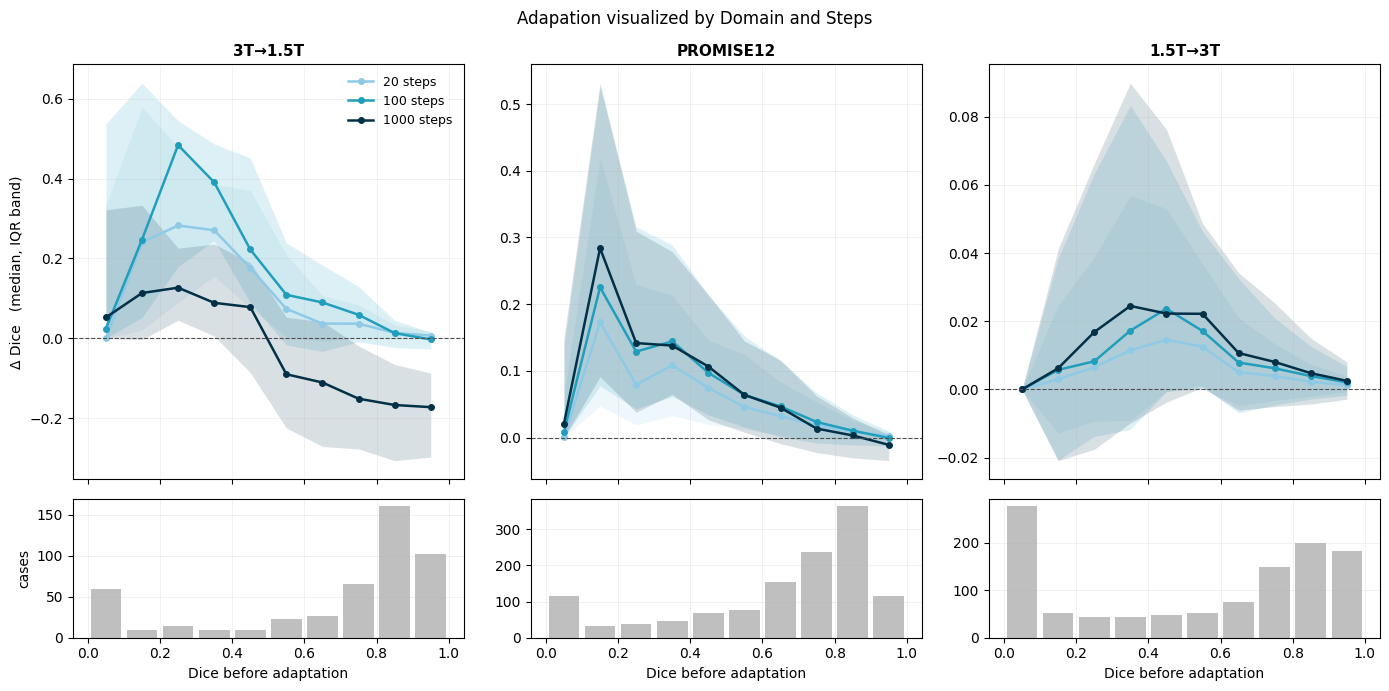

Δ | before < 0.25  Δ | 0.25–0.75  Δ | before > 0.75  n < 0.25  n > 0.75
domain    budget                                                                         
3T→1.5T   20                  0.191          0.106              0.018      74.0     299.0
          100                 0.271          0.135              0.006      74.0     299.0
          1000                0.185         -0.063             -0.193      74.0     299.0
PROMISE12 20                  0.114          0.069              0.013     168.0     611.0
          100                 0.163          0.087              0.010     168.0     611.0
          1000                0.165          0.077             -0.006     168.0     611.0
1.5T→3T   20                  0.003          0.025              0.004     350.0     460.0
          100                 0.005          0.033              0.005     350.0     460.0
          1000                0.006          0.036              0.005     350.0     460.0

In [5]:
BINS = np.arange(0, 1.01, 0.1)
BIN_CENTRES = (BINS[:-1] + BINS[1:]) / 2
BUDGET_COLOUR = {20: "#8ecae6", 100: "#219ebc", 1000: "#023047"}


def plot_delta_vs_baseline(frame, by="budget", colours=BUDGET_COLOUR,
                           title="Adapation visualized by Domain and Steps"):
    """One line per level of `by`; the levels drawn are the keys of `colours`."""
    levels = list(colours)
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True,
                             gridspec_kw={"height_ratios": [3, 1]})
    for j, domain in enumerate(ORDER):
        ax, ax_n = axes[0, j], axes[1, j]
        sub = frame[frame.domain == domain]
        for level in levels:
            s = sub[sub[by] == level]
            grouped = s.groupby(pd.cut(s.dice_before, BINS, include_lowest=True),
                                observed=False).delta_dice
            ax.fill_between(BIN_CENTRES, grouped.quantile(0.25), grouped.quantile(0.75),
                            color=colours[level], alpha=0.15, lw=0)
            ax.plot(BIN_CENTRES, grouped.median(), "o-", color=colours[level],
                    ms=4, lw=1.8, label=f"{level} steps" if by == "budget" else level)
        ax.axhline(0, color="0.3", lw=0.8, ls="--")
        ax.set_title(domain, fontsize=11, fontweight="bold")
        ax.grid(alpha=0.25, lw=0.5)

        base = sub[sub[by] == levels[0]]
        counts = base.groupby(pd.cut(base.dice_before, BINS, include_lowest=True),
                              observed=False).size() / len(PREDICTORS)
        ax_n.bar(BIN_CENTRES, counts, width=0.085, color="0.75")
        ax_n.set_xlabel("Dice before adaptation")
        ax_n.grid(alpha=0.25, lw=0.5)
        if j == 0:
            ax.set_ylabel("Δ Dice   (median, IQR band)")
            ax.legend(frameon=False, fontsize=9)
            ax_n.set_ylabel("cases")
    #fig.suptitle("Adaptation rescues broken cases and erodes good ones", fontsize=12, y=0.99)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


def delta_by_baseline(frame, by="budget"):
    """Numeric companion to plot_delta_vs_baseline."""
    return frame.groupby(["domain", by], observed=True).apply(
        lambda g: pd.Series({
            "Δ | before < 0.25": g.loc[g.dice_before < 0.25, "delta_dice"].mean(),
            "Δ | 0.25–0.75": g.loc[g.dice_before.between(0.25, 0.75), "delta_dice"].mean(),
            "Δ | before > 0.75": g.loc[g.dice_before > 0.75, "delta_dice"].mean(),
            "n < 0.25": (g.dice_before < 0.25).sum() // len(PREDICTORS),
            "n > 0.75": (g.dice_before > 0.75).sum() // len(PREDICTORS),
        }), include_groups=False)


plot_delta_vs_baseline(df)
plt.show()

delta_by_baseline(df).round(3)

## 3 · What a stopping rule is worth

Three policies on the same 1000-step trajectories:

| policy | what it needs |
|---|---|
| **run to the budget** | nothing — this is what the pickles' `dice_after` is |
| **best global step `t*`** | one step count tuned on the whole target domain (still label-free at test time only if `t*` transfers) |
| **per-case oracle** | ground truth per case — an upper bound, not achievable |

The gap between the second and third column is what `stop_rule: fg-drift` is trying to recover.

,Dice before,Δ run to end,Δ best global t*,Δ per-case oracle,t* per predictor
domain,,,,,
3T→1.5T,0.6774,-0.1059,0.0830,0.1142,"[56, 61, 62, 60, 65]"
PROMISE12,0.6420,0.0481,0.0609,0.0817,"[123, 110, 84, 114, 70]"
1.5T→3T,0.5257,0.0139,0.0140,0.0231,"[904, 997, 255, 992, 999]"


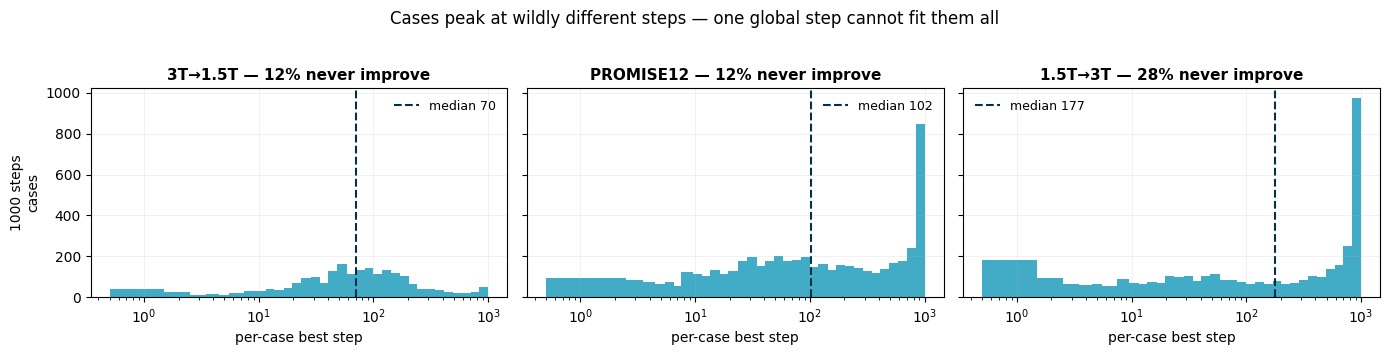

mean  median     p90     max
domain    budget                                
3T→1.5T   20      0.0054  0.0000  0.0156  0.3646
          100     0.0297  0.0098  0.0857  0.3890
          1000    0.2202  0.2003  0.4416  0.7103
PROMISE12 20      0.0056  0.0001  0.0176  0.1947
          100     0.0148  0.0042  0.0433  0.5502
          1000    0.0336  0.0135  0.0904  0.6428
1.5T→3T   20      0.0052  0.0002  0.0133  0.3355
          100     0.0078  0.0014  0.0198  0.2265
          1000    0.0091  0.0021  0.0241  0.3735

In [6]:
def stopping_policies(run=1000):
    rows = []
    for domain, label in DOMAINS.items():
        baseline, to_end, global_t, oracle, t_stars = [], [], [], [], []
        for p in PREDICTORS:
            C = curve(domain, run, p)
            start = C[:, 0]
            t_star = int(C.mean(0).argmax())     # one step for the whole domain
            t_stars.append(t_star)
            baseline.append(start.mean())
            to_end.append((C[:, -1] - start).mean())
            global_t.append((C[:, t_star] - start).mean())
            oracle.append((C.max(1) - start).mean())
        rows.append({
            "domain": label,
            "Dice before": np.mean(baseline),
            "Δ run to end": np.mean(to_end),
            "Δ best global t*": np.mean(global_t),
            "Δ per-case oracle": np.mean(oracle),
            "t* per predictor": t_stars,
        })
    return pd.DataFrame(rows).set_index("domain")


display(stopping_policies(1000).round(4))


def plot_best_step(frame, runs=(1000,)):
    """One row of histograms per run."""
    names = [resolve(r) for r in runs]
    fig, axes = plt.subplots(len(names), 3, figsize=(14, 3.4 * len(names)),
                             sharey="row", squeeze=False)
    for i, name in enumerate(names):
        steps = RUNS[name].steps
        # integer-aligned log bins, so short budgets do not get empty slivers between steps
        edges = np.unique(np.round(np.logspace(0, np.log10(steps), 40))) - 0.5
        edges = np.append(edges, steps + 0.5)
        for ax, domain in zip(axes[i], ORDER):
            s = frame[(frame.domain == domain) & (frame.run == name)]
            never = (s.best_step == 0).mean() * 100
            moved = s[s.best_step > 0].best_step
            ax.hist(moved, bins=edges, color="#219ebc", alpha=0.85)
            if len(moved):
                ax.axvline(moved.median(), color="#023047", lw=1.5, ls="--",
                           label=f"median {int(moved.median())}")
                ax.legend(frameon=False, fontsize=9)
            ax.set_xscale("log")
            ax.set_title(f"{domain} — {never:.0f}% never improve", fontsize=11, fontweight="bold")
            ax.set_xlabel("per-case best step")
            ax.grid(alpha=0.25, lw=0.5)
        axes[i, 0].set_ylabel(f"{name}\ncases")
    fig.suptitle("Cases peak at wildly different steps — one global step cannot fit them all",
                 fontsize=12, y=1.03 if len(names) == 1 else 1.0)
    fig.tight_layout()
    return fig


plot_best_step(df)
plt.show()

# per-case regret: how much the fixed budget throws away after the case's own peak
df.groupby(["domain", "budget"], observed=True).regret.agg(
    ["mean", "median", ("p90", lambda s: s.quantile(0.9)), "max"]).round(4)

## 4 · Is "this case improves" a property of the case or of the predictor?

Spearman ρ between the per-case Δ of different predictors. The **rerun** column is the ceiling:
the same predictor at the same step count, but two independent runs — anything below that is
genuine predictor disagreement rather than GPU non-determinism.

In [7]:
def predictor_agreement(run, ceiling_run=1000):
    """ceiling_run=None skips the rerun ceiling -- it is only meaningful when `ceiling_run`
    used the same predictor checkpoints and the same adaptation as `run`."""
    name = resolve(run)
    steps = RUNS[name].steps
    rows = []
    for domain, label in DOMAINS.items():
        deltas = np.stack([curve(domain, name, p)[:, -1] - curve(domain, name, p)[:, 0]
                           for p in PREDICTORS])
        rho = spearmanr(deltas.T).statistic
        off_diag = rho[np.triu_indices(len(PREDICTORS), 1)]
        row = {"domain": label, "run": name,
               "ρ across predictors": off_diag.mean(),
               "ρ min": off_diag.min(), "ρ max": off_diag.max()}

        if ceiling_run is not None:
            # repeatability ceiling: identical predictor and step count, independent run
            ceiling = []
            for p in PREDICTORS:
                own = curve(domain, name, p)
                long = curve(domain, ceiling_run, p)
                ceiling.append(spearmanr(own[:, steps] - own[:, 0],
                                         long[:, steps] - long[:, 0]).statistic)
            row["ρ rerun (ceiling)"] = np.mean(ceiling)
        rows.append(row)
    return pd.DataFrame(rows)


pd.concat([predictor_agreement(b) for b in [20, 100]], ignore_index=True).round(3)

,domain,run,ρ across predictors,ρ min,ρ max,ρ rerun (ceiling)
0,3T→1.5T,20 steps,0.749,0.701,0.781,0.994
1,PROMISE12,20 steps,0.635,0.551,0.695,0.982
2,1.5T→3T,20 steps,0.311,0.239,0.380,0.821
3,3T→1.5T,100 steps,0.733,0.667,0.780,0.986
4,PROMISE12,100 steps,0.646,0.573,0.709,0.968
5,1.5T→3T,100 steps,0.347,0.297,0.408,0.840


## 5 · When adaptation turns harmful

Top row: the mean Dice trajectory with the 10 most-helped (blue) and 10 most-harmed (red)
individual cases of predictor 0 drawn through it. Bottom row: the share of cases that are more
than 0.05 Dice above / below where they started, as a function of step. The dashed line is the
step at which the *mean* peaks — the point a global stopping rule would pick.

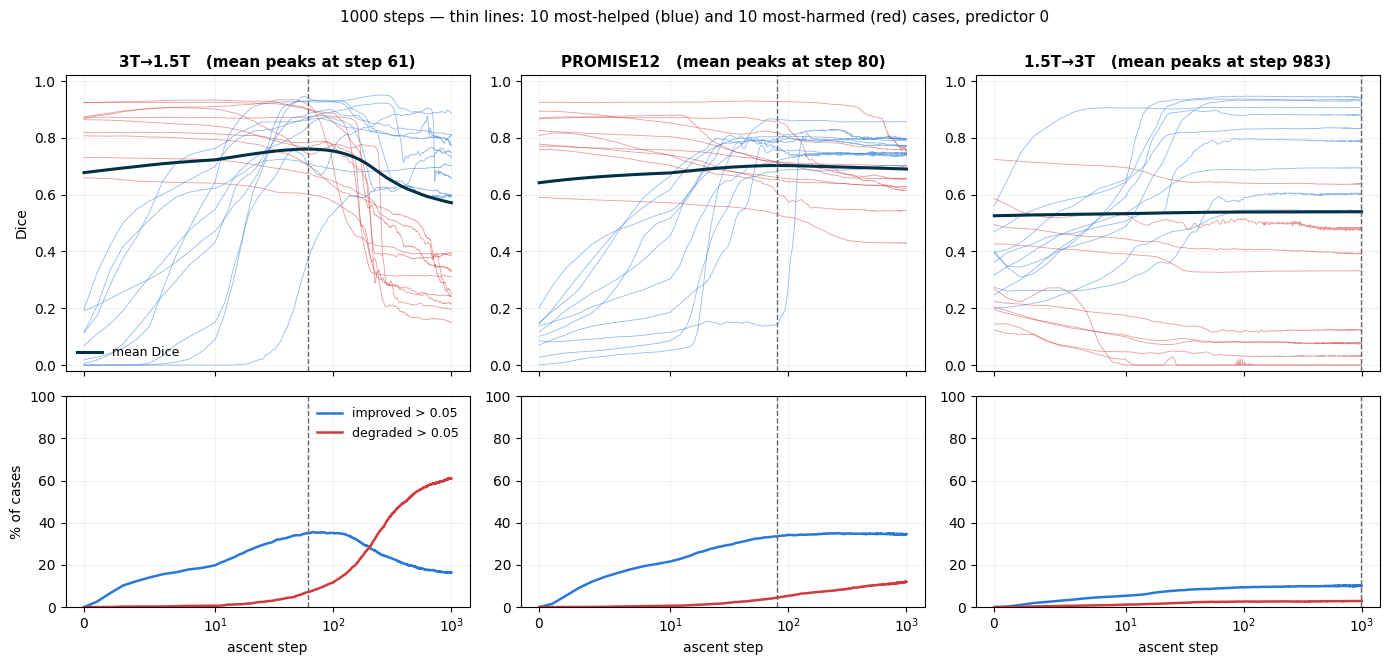

,peak helped %,at step,harmed % @ budget,harm overtakes gain at step
domain,,,,
3T→1.5T,35.6,68,61.0,202.0
PROMISE12,35.0,250,12.0,NaN
1.5T→3T,10.2,974,2.9,NaN


In [8]:
TOL = 0.05  # a Dice move worth calling a change


def plot_harm_accumulation(run=1000, tol=TOL, n_extreme=10):
    name = resolve(run)
    fig, axes = plt.subplots(2, 3, figsize=(14, 6.6), sharex=True,
                             gridspec_kw={"height_ratios": [1.4, 1]})
    steps = np.arange(RUNS[name].steps + 1)
    summary = []
    for j, (domain, label) in enumerate(DOMAINS.items()):
        ax, ax_f = axes[0, j], axes[1, j]
        pooled = np.concatenate([curve(domain, name, p) for p in PREDICTORS])
        start = pooled[:, [0]]
        helped = (pooled > start + tol).mean(0) * 100
        harmed = (pooled < start - tol).mean(0) * 100
        t_star = int(pooled.mean(0).argmax())

        first = curve(domain, name, 0)
        ranked = np.argsort(first[:, -1] - first[:, 0])
        for i in ranked[:n_extreme]:
            ax.plot(steps, first[i], color="#d03b3b", lw=0.6, alpha=0.5)
        for i in ranked[-n_extreme:]:
            ax.plot(steps, first[i], color="#2a78d6", lw=0.6, alpha=0.5)
        ax.plot(steps, pooled.mean(0), color="#023047", lw=2.2, label="mean Dice")
        ax.axvline(t_star, color="0.4", ls="--", lw=1)
        ax.set_xscale("symlog", linthresh=10)
        ax.set_ylim(-0.02, 1.02)
        ax.set_title(f"{label}   (mean peaks at step {t_star})", fontsize=11, fontweight="bold")
        ax.grid(alpha=0.25, lw=0.5)

        ax_f.plot(steps, helped, color="#2a78d6", lw=1.8, label=f"improved > {tol}")
        ax_f.plot(steps, harmed, color="#d03b3b", lw=1.8, label=f"degraded > {tol}")
        ax_f.axvline(t_star, color="0.4", ls="--", lw=1)
        ax_f.set_ylim(0, 100)
        ax_f.set_xlabel("ascent step")
        ax_f.grid(alpha=0.25, lw=0.5)
        if j == 0:
            ax.set_ylabel("Dice")
            ax.legend(frameon=False, fontsize=9, loc="lower left")
            ax_f.set_ylabel("% of cases")
            ax_f.legend(frameon=False, fontsize=9)

        crossover = np.where(harmed > helped)[0]
        summary.append({
            "domain": label,
            "peak helped %": helped.max(),
            "at step": int(helped.argmax()),
            "harmed % @ budget": harmed[-1],
            "harm overtakes gain at step": int(crossover[0]) if len(crossover) else None,
        })
    fig.suptitle(f"{name} — thin lines: 10 most-helped (blue) and 10 most-harmed (red) cases, "
                 "predictor 0", fontsize=11, y=1.0)
    fig.tight_layout()
    return fig, pd.DataFrame(summary).set_index("domain")


fig, crossover_table = plot_harm_accumulation(1000)
plt.show()
crossover_table.round(1)

## What the per-case view says

1. **The mean is a bad summary.** At 20 steps every domain looks like a modest win. Split by
   baseline Dice and it is two opposite effects superimposed: large gains concentrated on cases
   that started between 0.1 and 0.4 Dice, and a slow erosion of everything above 0.75.
   Cases that started below 0.1 are a bimodal minority: the median one barely moves
   (median Δ ≈ 0.00 at 20 steps, 0.02–0.05 at 1000), but a few are rescued outright —
   9% of PROMISE12's sub-0.1 cases end above 0.5 Dice, 13% on 3T→1.5T, and 0% on 1.5T→3T.

2. **More steps makes the trade worse, not better.** Reward/risk falls monotonically with
   budget in all three domains. On 3T→1.5T it inverts completely: at 1000 steps the mean Δ is
   negative, 70% of cases are harmed, and ~18% of cases that were above 0.5 Dice are pushed
   below it.

3. **The 1.5T→3T failure is different in kind.** Its curves are flat rather than collapsing,
   its reward/risk is stuck near 3 at every budget, and predictors agree with each other only at
   ρ≈0.31 despite a rerun ceiling of ≈0.98. The ascent raises μ̂ without moving the mask —
   the predictor is not tracking Dice in that domain, so there is nothing for a stopping rule
   to stop.

4. **A single global stopping step recovers most, but not all, of the oracle.** Choosing `t*`
   per domain turns 3T→1.5T from −0.106 into +0.083 (oracle +0.114) and lifts PROMISE12 from
   +0.048 to +0.061 (oracle +0.082). The residual gap is real per-case heterogeneity: the
   per-case best step spans the full 1–1000 range with a large spike at both ends.

5. **A safety metric belongs in the paper.** `broke <0.5 %` — usable segmentations destroyed —
   separates the three domains and the three budgets far more sharply than mean Δ does.

## 6 · Selektive Adaption — nur die unsichersten Cases anfassen

Section 2 hat gezeigt, dass Gewinne und Schäden auf verschiedenen Cases landen: adaptiert wird
alles, profitieren tun die kaputten Cases, bezahlen die guten. Naheliegende Konsequenz: **gar nicht
erst alles adaptieren**, sondern nur die Cases, denen der Score-Predictor selbst ein niedriges
μ̂ gibt.

Das lässt sich vollständig aus den vorhandenen Pickles simulieren — `mu_before` liegt pro Case vor,
und `dice_per_step` liefert jeden Stopp-Zeitpunkt. Kein neuer Run nötig.

**Die Schwelle ist kein freier Hyperparameter.** Zwei Entscheidungen halten sie fest:

* Nicht eine *absolute* Schwelle auf μ̂, sondern ein **Quantil der μ̂-Verteilung auf der
  Zieldomäne** — „adaptiere die untersten 30 %". Das ist label-frei, braucht keinen Val-Split und
  ist immun gegen den Kalibrierungs-Bias (siehe Zelle unten: der beträgt auf 1.5T→3T +0.21, eine
  feste Schwelle wäre dort völlig anders positioniert als auf PROMISE12).
* Der Betriebspunkt wird nicht behauptet, sondern aus der **Risk–Coverage-Kurve** abgelesen, und
  die Kurve selbst ist das Ergebnis, das ins Paper gehört — so wie in der Selective-Prediction-
  Literatur. Die 30 % unten sind das Knie dieser Kurve, kein geratener Wert.

In [9]:
# Bester globaler Stopp pro Domain, aus Abschnitt 3
T_STAR = {"promise12": 100, "threet-to-onepointfivet": 61, "onepointfivet-to-threet": 1000}
COVERAGE = 0.30  # gewählter Betriebspunkt, unten aus dem Knie der Retention-Kurve begründet


def pooled(domain, step, run=1000):
    """(mu_before, dice_before, dice_at_step) über alle 5 Predictors gepoolt.

    Standardmäßig aus den 1000-Schritt-Runs, damit jeder Stopp-Zeitpunkt aus *derselben*
    Trajektorie kommt und der Vergleich der Budgets nicht Run-Rauschen einsammelt.
    """
    mu, before, after = [], [], []
    for p in PREDICTORS:
        ev = load_run(domain, run, p)[1]
        C = ev["dice_per_step"].float().numpy()
        mu.append(ev["mu_before"].float().numpy())
        before.append(C[:, 0])
        after.append(C[:, step])
    return np.concatenate(mu), np.concatenate(before), np.concatenate(after)


def gate_stats(gate, before, after):
    final = np.where(gate, after, before)
    d = final - before
    adapted = d[gate] if gate.any() else np.zeros(1)
    return {
        "adapt %": 100 * gate.mean(),
        "Dice": final.mean(),
        "Δ": d.mean(),
        "harmed %": 100 * (d < -1e-3).mean(),
        "broke <0.5 %": 100 * ((before >= 0.5) & (final < 0.5)).mean(),
        "Δ | adaptiert": adapted.mean(),
        "harmed % | adaptiert": 100 * (adapted < -1e-3).mean(),
    }


def order_domains(frame, level="domain"):
    """Domains in Reihenfolge von DOMAINS statt alphabetisch."""
    out = frame.copy()
    out[level] = pd.Categorical(out[level], ORDER, ordered=True)
    return out.sort_values(level, kind="stable")


def gate_table(run=1000, t_star=T_STAR):
    rows = []
    for domain, label in DOMAINS.items():
        mu, before, after = pooled(domain, t_star[domain], run)
        gates = [("alle", np.ones_like(mu, dtype=bool))]
        gates += [(f"unterste {int(q*100)} % μ̂", mu < np.quantile(mu, q)) for q in (0.5, 0.3, 0.2)]
        gates += [("keine", np.zeros_like(mu, dtype=bool))]
        for name, gate in gates:
            rows.append({"domain": label, "t*": t_star[domain], "gate": name,
                         **gate_stats(gate, before, after)})
    return order_domains(pd.DataFrame(rows)).set_index(["domain", "t*", "gate"])


gate_table().round(3)

adapt %   Dice      Δ  harmed %  broke <0.5 %  Δ | adaptiert  harmed % | adaptiert
domain    t*   gate                                                                                                
3T→1.5T   61   alle              100.000  0.760  0.083    25.738         0.998          0.083                25.738
               unterste 50 % μ̂   49.979  0.754  0.077     7.942         0.915          0.154                15.890
               unterste 30 % μ̂   30.021  0.747  0.070     2.079         0.249          0.232                 6.925
               unterste 20 % μ̂   20.000  0.734  0.057     0.457         0.042          0.284                 2.287
               keine               0.000  0.677  0.000     0.000         0.000          0.000                 0.000
PROMISE12 100  alle              100.000  0.702  0.060    26.458         0.272          0.060                26.458
               unterste 50 % μ̂   50.000  0.695  0.053     8.349         0.208          0.107                16.699
               unterste 30 % μ̂   30.000  0.685  0.043     3.333         0.128          0.143                11.111
               unterste 20 % μ̂   20.000  0.674  0.032     1.763         0.096          0.159                 8.814
               keine               0.000  0.642  0.000     0.000         0.000          0.000                 0.000
1.5T→3T   1000 alle              100.000  0.540  0.014    28.921         0.357          0.014                28.921
               unterste 50 % μ̂   49.991  0.538  0.012    12.971         0.268          0.024                25.946
               unterste 30 % μ̂   30.009  0.536  0.010     6.548         0.143          0.034                21.819
               unterste 20 % μ̂   20.000  0.533  0.008     4.175         0.054          0.038                20.874
               keine               0.000  0.526  0.000     0.000         0.000          0.000                 0.000

Die letzten beiden Spalten sind der eigentliche Beleg: das Gate reduziert nicht bloß die
**Exposition** (weniger Cases angefasst ⇒ automatisch weniger Schaden), es selektiert eine
*bessere Population*. Auf 3T→1.5T steigt Δ **pro adaptiertem Case** von +0.083 auf +0.232 und die
Schadensquote unter den adaptierten fällt von 25.7 % auf 6.9 %.

Auf 1.5T→3T passiert genau das nicht — dort fällt die Schadensquote unter den adaptierten nur von
28.9 % auf 21.8 %. μ̂ trennt in dieser Domäne zu schlecht, konsistent mit allem anderen aus
Abschnitt 4.

In [10]:
def retention(domain, step=None, run=1000):
    """Welcher Anteil des Gesamtgewinns / Gesamtschadens bleibt bei Coverage q übrig."""
    step = T_STAR[domain] if step is None else step
    mu, before, after = pooled(domain, step, run)
    d = after - before
    order = np.argsort(mu)
    total_gain = np.clip(d, 0, None).sum()
    total_harm = -np.clip(d, None, 0).sum()
    qs = np.arange(0.05, 1.001, 0.05)
    gain = np.array([np.clip(d[order[:int(len(mu) * q)]], 0, None).sum() / total_gain for q in qs])
    harm = np.array([-np.clip(d[order[:int(len(mu) * q)]], None, 0).sum() / total_harm for q in qs])
    return qs, gain, harm


def knee_table(run=1000, t_star=T_STAR):
    knee = []
    for domain, label in DOMAINS.items():
        qs, gain, harm = retention(domain, t_star[domain], run)
        k = int(np.argmax(gain - harm))          # Youden-artig: maximaler Abstand zur Diagonale
        knee.append({"domain": label, "Knie-Coverage": f"{qs[k]:.0%}",
                     "Gewinn behalten": gain[k], "Schaden behalten": harm[k],
                     f"Gewinn @ {COVERAGE:.0%}": gain[int(round(COVERAGE / 0.05)) - 1],
                     f"Schaden @ {COVERAGE:.0%}": harm[int(round(COVERAGE / 0.05)) - 1]})
    return order_domains(pd.DataFrame(knee)).set_index("domain")


print("Knie der Retention-Kurve pro Domain — deshalb 30 % als gemeinsamer Betriebspunkt:")
knee_table().round(3)

Knie der Retention-Kurve pro Domain — deshalb 30 % als gemeinsamer Betriebspunkt:


,Knie-Coverage,Gewinn behalten,Schaden behalten,Gewinn @ 30%,Schaden @ 30%
domain,,,,,
3T→1.5T,25%,0.709,0.053,0.762,0.133
PROMISE12,35%,0.704,0.217,0.644,0.163
1.5T→3T,30%,0.616,0.371,0.616,0.371


Die drei Knie liegen bei 35 % / 25 % / 30 %. **30 % ist der gemeinsame Betriebspunkt**, den alle
drei Domänen tragen — nicht per Hand gewählt, sondern als Maximum von
(behaltener Gewinn − behaltener Schaden).

### Risk–Coverage: ist μ̂ überhaupt das richtige Auswahlsignal?

Drei Auswahlregeln bei identischem Budget und identischer Coverage:

* **μ̂** — einsetzbar, label-frei
* **Zufall** — die Nulllinie; jede Kurve darüber zeigt, dass das Signal Information trägt
* **Orakel auf echtem `dice_before`** — braucht Ground Truth, obere Schranke für „sortiere nach
  Baseline-Qualität"

Untere Reihe: der Sicherheits-Preis derselben Regel. Dass die Orakel-Kurve dort lange auf 0 liegt,
ist kein Verdienst — sie sortiert per Definition alle Cases mit `dice_before` < 0.5 nach vorne, und
die *können* die Schwelle 0.5 gar nicht mehr unterschreiten.

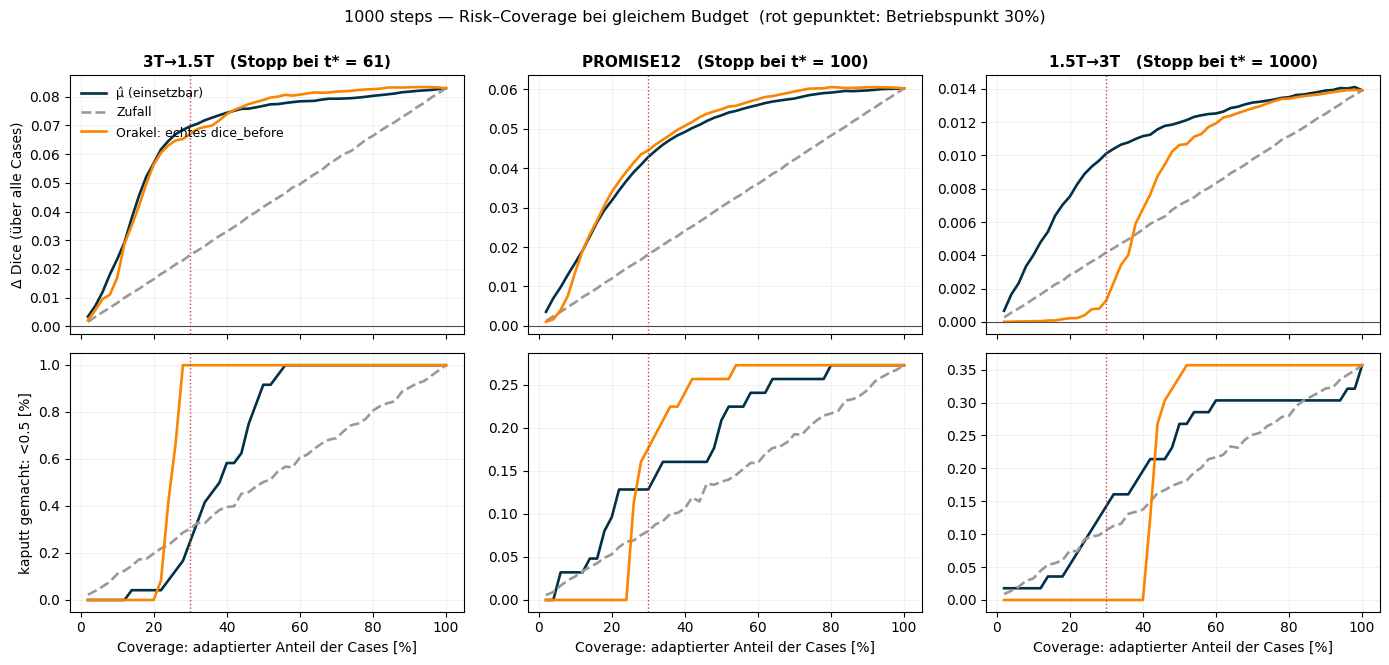

In [11]:
COVERAGES = np.arange(0.02, 1.001, 0.02)
SIGNAL_COLOUR = {"μ̂ (einsetzbar)": "#023047", "Zufall": "0.6", "Orakel: echtes dice_before": "#fb8500"}


def plot_risk_coverage(step_of=None, n_random=100, seed=0, run=1000):
    step_of = step_of or (lambda d: T_STAR[d])
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(2, 3, figsize=(14, 6.6), sharex=True)
    for j, (domain, label) in enumerate(DOMAINS.items()):
        step = step_of(domain)
        mu, before, after = pooled(domain, step, run)
        d = after - before
        n = len(mu)
        ranking = {"μ̂ (einsetzbar)": np.argsort(mu),
                   "Orakel: echtes dice_before": np.argsort(before)}
        for name, colour in SIGNAL_COLOUR.items():
            gains, broke = [], []
            for c in COVERAGES:
                k = max(int(n * c), 1)
                if name == "Zufall":
                    picks = [rng.choice(n, k, replace=False) for _ in range(n_random)]
                    gains.append(np.mean([d[s].sum() / n for s in picks]))
                    broke.append(np.mean([100 * ((before[s] >= .5) & (after[s] < .5)).sum() / n
                                          for s in picks]))
                else:
                    s = ranking[name][:k]
                    gains.append(d[s].sum() / n)
                    broke.append(100 * ((before[s] >= .5) & (after[s] < .5)).sum() / n)
            style = "--" if name == "Zufall" else "-"
            axes[0, j].plot(COVERAGES * 100, gains, style, color=colour, lw=1.9, label=name)
            axes[1, j].plot(COVERAGES * 100, broke, style, color=colour, lw=1.9)
        for ax in (axes[0, j], axes[1, j]):
            ax.axvline(COVERAGE * 100, color="#d03b3b", lw=1, ls=":")
            ax.grid(alpha=0.25, lw=0.5)
        axes[0, j].axhline(0, color="0.3", lw=0.8)
        axes[0, j].set_title(f"{label}   (Stopp bei t* = {step})", fontsize=11, fontweight="bold")
        axes[1, j].set_xlabel("Coverage: adaptierter Anteil der Cases [%]")
        if j == 0:
            axes[0, j].set_ylabel("Δ Dice (über alle Cases)")
            axes[1, j].set_ylabel("kaputt gemacht: <0.5 [%]")
            axes[0, j].legend(frameon=False, fontsize=9, loc="upper left")
    fig.suptitle(f"{resolve(run)} — Risk–Coverage bei gleichem Budget  "
                 f"(rot gepunktet: Betriebspunkt {COVERAGE:.0%})", fontsize=11.5, y=1.0)
    fig.tight_layout()
    return fig


plot_risk_coverage()
plt.show()

### Kalibrierung von μ̂ — die Voraussetzung für das Gate

Das Gate steht und fällt damit, dass μ̂ und der echte Dice zusammenhängen. Der Rang-Zusammenhang
ist das, worauf es ankommt (das Gate sortiert nur), der Bias ist das, was eine *absolute* Schwelle
kaputt machen würde.

In [12]:
def calibration(run):
    rows = []
    for domain, label in DOMAINS.items():
        for split in ("val", "test"):
            evs = [load_run(domain, run, p, split)[1] for p in PREDICTORS]
            mu = np.concatenate([e["mu_before"].float().numpy() for e in evs])
            dice = np.concatenate([e["dice_before"].float().numpy() for e in evs])
            rows.append({"domain": label, "split": split, "n": len(dice) // len(PREDICTORS),
                         "Dice": dice.mean(), "μ̂": mu.mean(), "Bias": mu.mean() - dice.mean(),
                         "Pearson": pearsonr(mu, dice)[0], "Spearman": spearmanr(mu, dice).statistic})
    return order_domains(pd.DataFrame(rows)).set_index(["domain", "split"])


calibration(BUDGETS[0]).round(3)

n   Dice     μ̂   Bias  Pearson  Spearman
domain    split                                              
3T→1.5T   val     103  0.860  0.866  0.005    0.545     0.701
          test    481  0.677  0.674 -0.004    0.921     0.846
PROMISE12 val      64  0.862  0.895  0.033    0.771     0.803
          test   1248  0.642  0.632 -0.010    0.855     0.817
1.5T→3T   val      49  0.867  0.925  0.058    0.390     0.749
          test   1121  0.526  0.732  0.206    0.672     0.713

`val` ist die Quelldomäne (Dice ≈ 0.86), `test` die verschobene Zieldomäne. Der Rang-Zusammenhang
hält überall (Spearman 0.70–0.85), aber der Bias springt von −0.01 auf **+0.21** auf 1.5T→3T. Genau
deshalb Quantil statt fester Schwelle: eine auf `val` kalibrierte Zahl würde auf 1.5T→3T entweder
alles oder nichts adaptieren.

### Fazit zum Gate

1. **30 % Coverage bei t\* ist der beste Sicherheits-Trade in den Daten.** Auf 3T→1.5T: Δ +0.070
   statt +0.083 (84 % des Gewinns), harmed 2.1 % statt 25.7 %, `broke <0.5` 0.25 % statt 1.00 %.
2. **μ̂ ist ein echtes Auswahlsignal**, 2–3× besser als Zufall bei gleicher Coverage und praktisch
   gleichauf mit dem Orakel auf dem echten `dice_before`. Auf 1.5T→3T schlägt μ̂ das Orakel sogar —
   die Cases mit dem niedrigsten echten Dice sind dort tote Cases, die sich gar nicht bewegen,
   während μ̂ die noch beweglichen findet.
3. **Das Gate ersetzt kein Early Stopping.** Bei 1000 Schritten rettet es 3T→1.5T zwar von −0.106
   auf +0.030, aber bei t* = 61 zu stoppen liefert allein schon +0.083. Erst beides zusammen ergibt
   den Betriebspunkt aus Punkt 1.
4. Auf **1.5T→3T bringt das Gate wenig** — dort ist nicht die Auswahl das Problem, sondern dass μ̂
   die Segmentierung gar nicht erst beeinflusst.

---

# 7 · Variants: pre-/post-norm predictor × with/without logit adapter

The same per-case analyses, with the step budget fixed at 100 and the *variant* as the compared
dimension:

| variant | folder | score predictor | adapted parameters |
|---|---|---|---|
| **post-norm** | `latent_tta_postnorm` | `post-norm_with_logits` | latent sites [0, 17] |
| **post-norm + logits** | `latent_tta_postnorm_logits` | `post-norm_with_logits` | sites + per-channel affine on the U-Net logits |
| **pre-norm** | `latent_tta_prenorm` | `pre_norm_with_logits` | latent sites [0, 17] |
| **pre-norm + logits** | `latent_tta_prenorm_logits` | `pre_norm_with_logits` | sites + per-channel affine on the U-Net logits |

* The loader checks `tta.max_steps`, `model.hook_placement` and `tta.adapt_logits` of every pickle
  against this table. A variant whose folder is not complete (3 domains × 5 predictors) is skipped
  with a message; everything below adapts to whichever variants are present.
  `run_tta100_queue.sh` produces it with `SCENARIOS=prenorm_logits`.
* Pre- and post-norm use **different predictor checkpoints** (the pre-norm ones carry the same
  names as in sections 1–6, the post-norm ones are the September retrain). Predictor *i* of one
  family has nothing to do with predictor *i* of the other, so cross-family comparisons pair by
  **case** only, averaged over the 5 predictors.
* All variants ran with batch size 8, the step-budget runs with 32. `dice_before` is bit-identical
  within each group, but differs by up to ~1e-3 between the groups.

In [13]:
VARIANT_COLOUR = {
    "post-norm": "#219ebc",
    "post-norm + logits": "#023047",
    "pre-norm": "#ffb703",
    "pre-norm + logits": "#d9480f",
}

VARIANTS = []
for name in VARIANT_NAMES:
    gone = missing_runs(name)
    if gone:
        print(f"skipping {name!r}: {len(gone)} of {len(DOMAINS) * len(PREDICTORS)} runs missing "
              f"in {RUNS[name].folder}/")
    else:
        VARIANTS.append(name)
assert VARIANTS, "no complete variant folder"
V_COLOUR = {v: VARIANT_COLOUR[v] for v in VARIANTS}

dfv = per_case_frame(VARIANTS)
check_case_alignment(VARIANTS)
print("max |dice_before variants − dice_before budget runs|:",
      {DOMAINS[d]: round(float((load_run(d, VARIANTS[0], 0)[1]["dice_before"]
                                - load_run(d, BUDGETS[0], 0)[1]["dice_before"]).abs().max()), 5)
       for d in DOMAINS})
print()
print(dfv.groupby(["domain", "run"], observed=True).size().unstack())

risk_reward(dfv, by="run").round(3)

case alignment OK — dice_before identical across all 20 runs per domain
max |dice_before variants − dice_before budget runs|: {'3T→1.5T': 0.0004, 'PROMISE12': 0.00091, '1.5T→3T': 0.00073}

run        post-norm  post-norm + logits  pre-norm  pre-norm + logits
domain                                                               
3T→1.5T         2405                2405      2405               2405
PROMISE12       6240                6240      6240               6240
1.5T→3T         5605                5605      5605               5605


cases  mean Δ  median Δ  helped %  harmed %  reward   risk  reward/risk  p01 Δ  p99 Δ  worst Δ  best Δ  broke <0.5 %  fixed <0.5 %
domain    run                                                                                                                                                    
3T→1.5T   post-norm            481.0   0.058     0.010    65.114    23.992   0.063  0.005       13.579 -0.067  0.699   -0.361   0.923         0.541         7.568
          post-norm + logits   481.0   0.059     0.011    66.403    23.077   0.064  0.005       13.461 -0.068  0.669   -0.373   0.924         0.624         7.734
          pre-norm             481.0   0.076     0.019    62.620    31.185   0.093  0.017        5.486 -0.195  0.802   -0.397   0.957         1.414         9.896
          pre-norm + logits    481.0   0.072     0.016    60.665    33.514   0.092  0.020        4.666 -0.212  0.789   -0.419   0.955         1.538        10.021
PROMISE12 post-norm           1248.0   0.055     0.022    72.404    20.994   0.060  0.005       11.816 -0.080  0.520   -0.207   0.854         0.176         7.452
          post-norm + logits  1248.0   0.056     0.023    72.949    21.138   0.061  0.005       11.506 -0.080  0.512   -0.201   0.853         0.192         7.564
          pre-norm            1248.0   0.060     0.022    67.772    26.843   0.068  0.009        7.981 -0.111  0.588   -0.439   0.857         0.321         8.782
          pre-norm + logits   1248.0   0.060     0.023    68.317    26.506   0.069  0.009        7.537 -0.117  0.592   -0.446   0.858         0.401         8.606
1.5T→3T   post-norm           1121.0   0.006     0.000    43.354    31.258   0.011  0.004        2.410 -0.071  0.150   -0.301   0.524         0.268         0.963
          post-norm + logits  1121.0   0.006     0.000    42.337    33.345   0.011  0.005        2.165 -0.075  0.145   -0.268   0.537         0.357         1.124
          pre-norm            1121.0   0.013     0.001    50.740    28.635   0.018  0.006        3.173 -0.090  0.279   -0.268   0.682         0.339         2.302
          pre-norm + logits   1121.0   0.014     0.001    49.991    29.081   0.019  0.005        3.601 -0.085  0.279   -0.360   0.644         0.250         2.373

## 7.1 · Where the gains and the losses live, per variant

Same as section 2: Δ Dice binned by baseline Dice, median line and IQR band, one colour per variant.

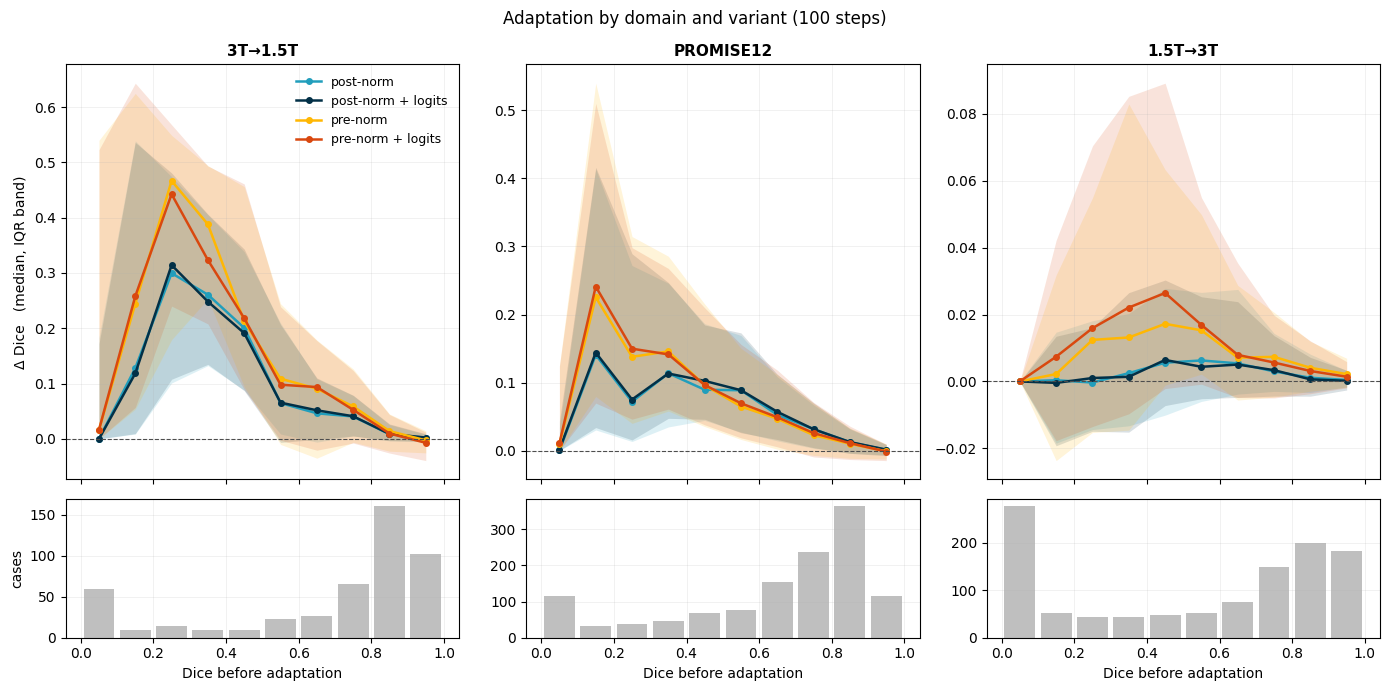

Δ | before < 0.25  Δ | 0.25–0.75  Δ | before > 0.75  n < 0.25  n > 0.75
domain    run                                                                                        
3T→1.5T   post-norm                       0.170          0.109              0.013      74.0     299.0
          post-norm + logits              0.170          0.109              0.013      74.0     299.0
          pre-norm                        0.270          0.134              0.007      74.0     299.0
          pre-norm + logits               0.271          0.131              0.001      74.0     299.0
PROMISE12 post-norm                       0.106          0.088              0.015     168.0     611.0
          post-norm + logits              0.110          0.089              0.015     168.0     611.0
          pre-norm                        0.163          0.087              0.010     168.0     611.0
          pre-norm + logits               0.162          0.089              0.010     168.0     611.0
1.5T→3T   post-norm                       0.001          0.016              0.004     350.0     460.0
          post-norm + logits              0.000          0.016              0.003     350.0     460.0
          pre-norm                        0.004          0.033              0.005     350.0     460.0
          pre-norm + logits               0.007          0.036              0.004     350.0     460.0

In [14]:
plot_delta_vs_baseline(dfv, by="run", colours=V_COLOUR,
                       title="Adaptation by domain and variant (100 steps)")
plt.show()

delta_by_baseline(dfv, by="run").round(3)

## 7.2 · Trajectories and stopping, per variant

Top row: mean Δ Dice over the ascent, pooled over the 5 predictors; the dot marks the step where
the mean peaks (`t*`). Bottom row: share of cases more than `TOL` above (solid) / below (dashed)
their starting Dice. Then the three stopping policies of section 3, the per-case best-step
histograms, and the regret of running to the budget.

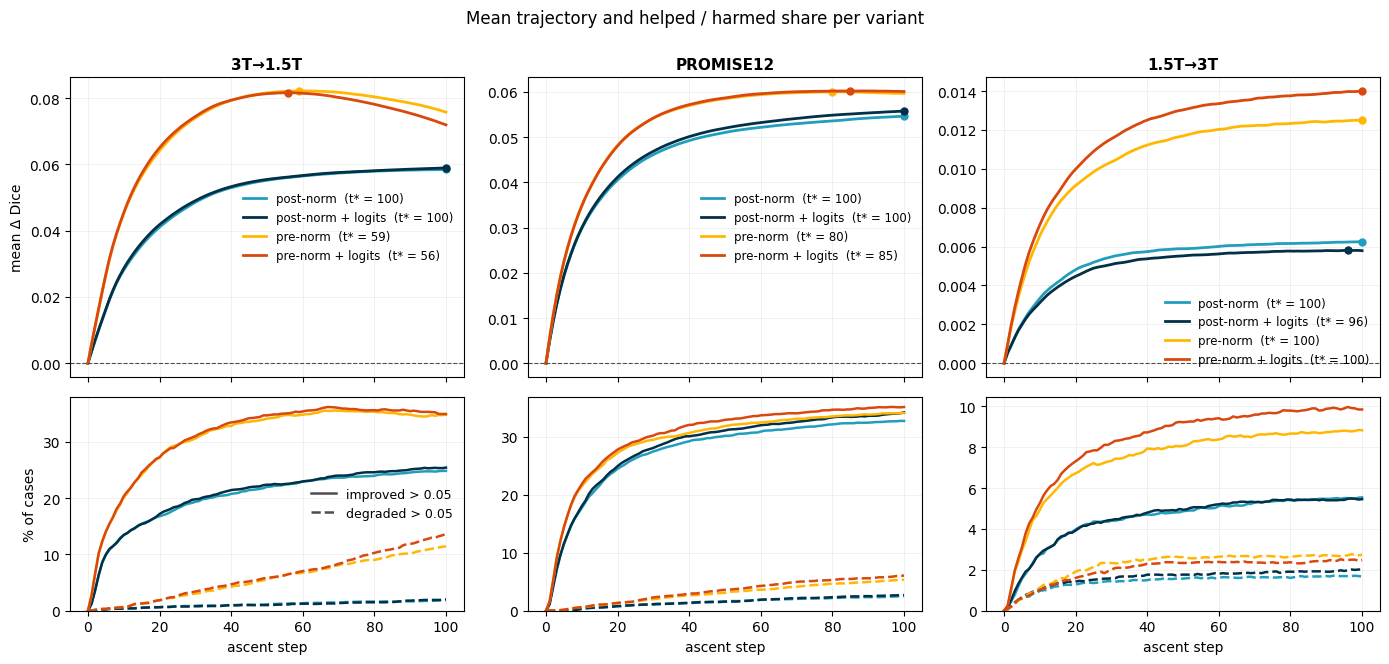

Dice before  Δ run to end  Δ best global t*  Δ per-case oracle           t* per predictor
run                domain                                                                                              
post-norm          3T→1.5T         0.6774        0.0585            0.0586             0.0660    [99, 70, 100, 100, 100]
                   PROMISE12       0.6420        0.0546            0.0546             0.0629  [100, 100, 100, 100, 100]
                   1.5T→3T         0.5257        0.0063            0.0063             0.0125    [99, 100, 100, 100, 92]
post-norm + logits 3T→1.5T         0.6774        0.0590            0.0590             0.0667    [99, 90, 100, 100, 100]
                   PROMISE12       0.6420        0.0558            0.0558             0.0644  [100, 100, 100, 100, 100]
                   1.5T→3T         0.5257        0.0058            0.0058             0.0126       [79, 99, 98, 68, 97]
pre-norm           3T→1.5T         0.6774        0.0758            0.0824             0.1055       [52, 54, 63, 68, 65]
                   PROMISE12       0.6420        0.0596            0.0602             0.0746      [99, 98, 80, 100, 68]
                   1.5T→3T         0.5257        0.0125            0.0125             0.0204    [100, 100, 98, 97, 100]
pre-norm + logits  3T→1.5T         0.6774        0.0719            0.0819             0.1054       [55, 54, 56, 68, 57]
                   PROMISE12       0.6420        0.0601            0.0605             0.0757       [99, 98, 88, 95, 68]
                   1.5T→3T         0.5257        0.0140            0.0140             0.0215   [99, 100, 100, 100, 100]

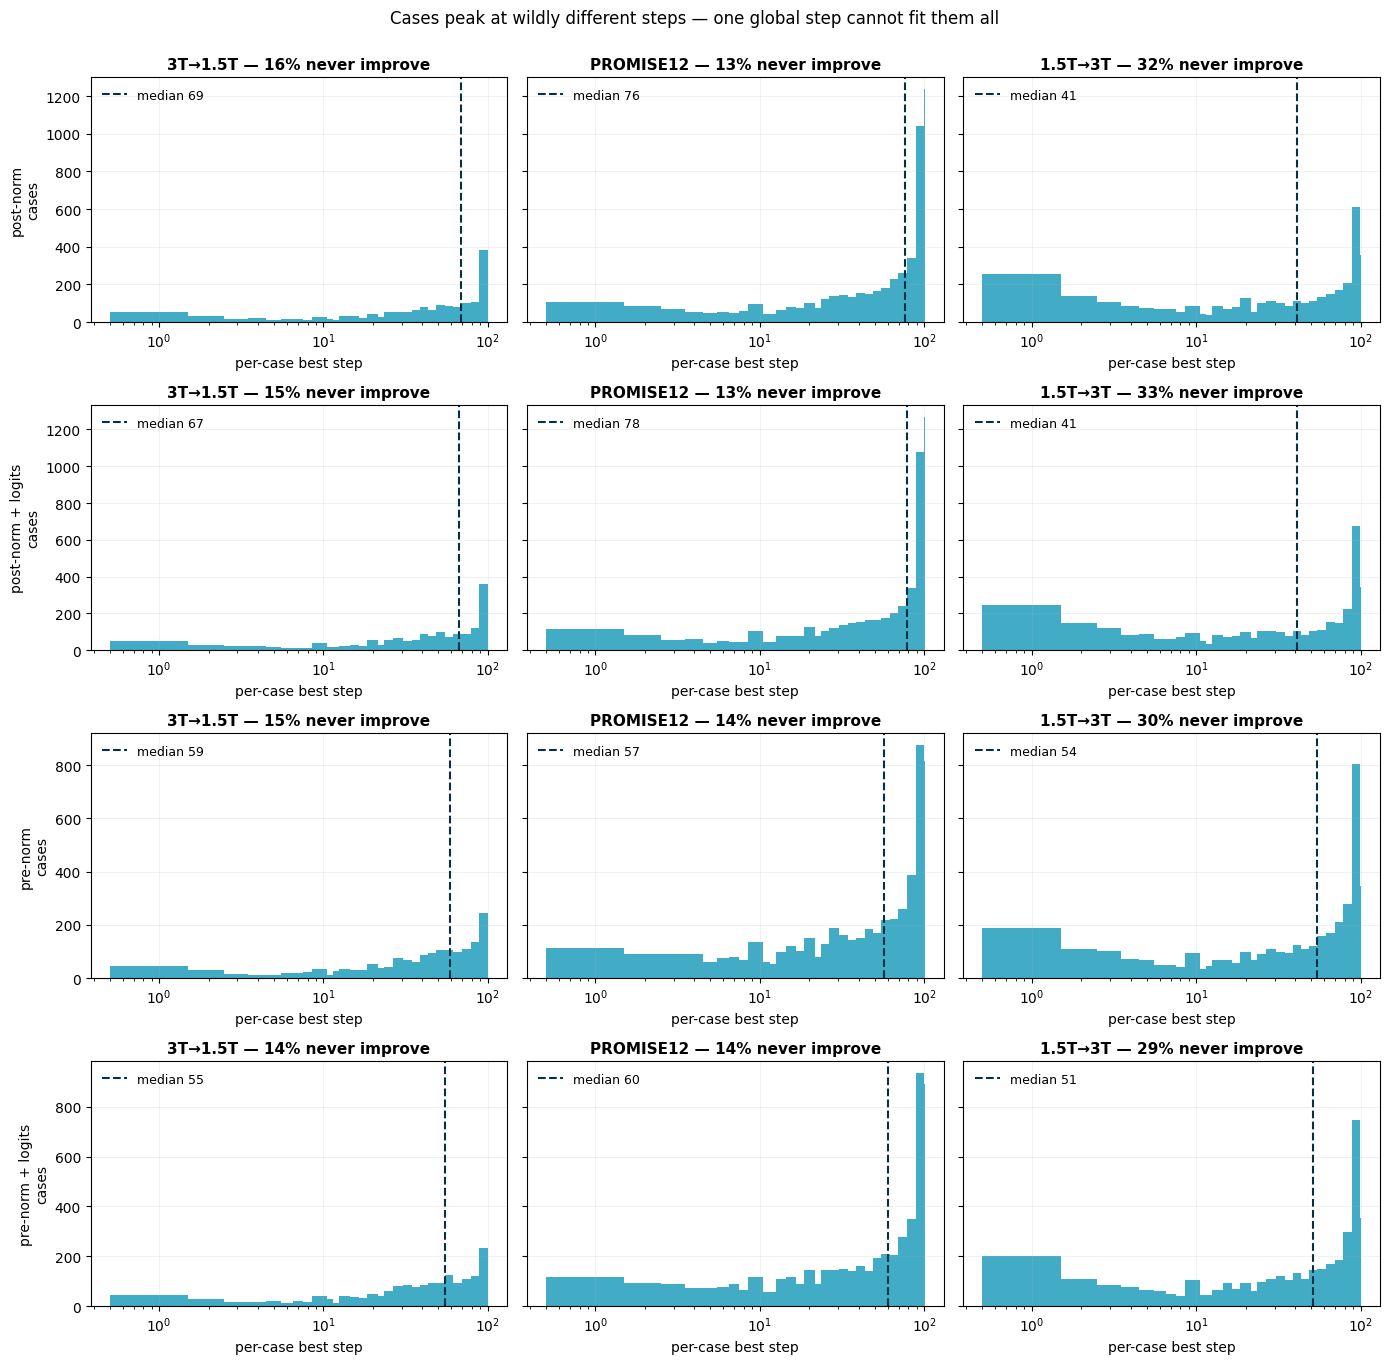

mean  median     p90     max
domain    run                                               
3T→1.5T   post-norm           0.0076  0.0013  0.0195  0.3614
          post-norm + logits  0.0077  0.0014  0.0197  0.3729
          pre-norm            0.0297  0.0095  0.0861  0.4261
          pre-norm + logits   0.0334  0.0126  0.0941  0.4190
PROMISE12 post-norm           0.0083  0.0014  0.0237  0.2392
          post-norm + logits  0.0086  0.0013  0.0257  0.2612
          pre-norm            0.0149  0.0044  0.0434  0.4591
          pre-norm + logits   0.0156  0.0042  0.0461  0.4561
1.5T→3T   post-norm           0.0063  0.0013  0.0159  0.3006
          post-norm + logits  0.0068  0.0014  0.0175  0.2684
          pre-norm            0.0079  0.0014  0.0206  0.2684
          pre-norm + logits   0.0075  0.0016  0.0197  0.3596

In [15]:
from matplotlib.lines import Line2D


def plot_variant_trajectories(runs, tol=TOL):
    fig, axes = plt.subplots(2, 3, figsize=(14, 6.6), sharex=True,
                             gridspec_kw={"height_ratios": [1.4, 1]})
    for j, (domain, label) in enumerate(DOMAINS.items()):
        ax, ax_f = axes[0, j], axes[1, j]
        for run in runs:
            C = np.concatenate([curve(domain, run, p) for p in PREDICTORS])
            steps = np.arange(C.shape[1])
            start = C[:, [0]]
            gain = C.mean(0) - start.mean()
            t_star = int(gain.argmax())
            colour = VARIANT_COLOUR[run]
            ax.plot(steps, gain, color=colour, lw=2, label=f"{run}  (t* = {t_star})")
            ax.plot(t_star, gain[t_star], "o", color=colour, ms=5)
            ax_f.plot(steps, (C > start + tol).mean(0) * 100, color=colour, lw=1.8)
            ax_f.plot(steps, (C < start - tol).mean(0) * 100, color=colour, lw=1.8, ls="--")
        ax.axhline(0, color="0.3", lw=0.8, ls="--")
        ax.set_title(label, fontsize=11, fontweight="bold")
        ax.legend(frameon=False, fontsize=8.5)
        ax.grid(alpha=0.25, lw=0.5)
        ax_f.set_ylim(0, None)
        ax_f.set_xlabel("ascent step")
        ax_f.grid(alpha=0.25, lw=0.5)
        if j == 0:
            ax.set_ylabel("mean Δ Dice")
            ax_f.set_ylabel("% of cases")
            ax_f.legend(handles=[Line2D([], [], color="0.3", lw=1.8, label=f"improved > {tol}"),
                                 Line2D([], [], color="0.3", lw=1.8, ls="--",
                                        label=f"degraded > {tol}")],
                        frameon=False, fontsize=9)
    fig.suptitle("Mean trajectory and helped / harmed share per variant", fontsize=12, y=1.0)
    fig.tight_layout()
    return fig


plot_variant_trajectories(VARIANTS)
plt.show()

display(pd.concat({v: stopping_policies(v) for v in VARIANTS}, names=["run"]).round(4))

plot_best_step(dfv, VARIANTS)
plt.show()

dfv.groupby(["domain", "run"], observed=True).regret.agg(
    ["mean", "median", ("p90", lambda s: s.quantile(0.9)), "max"]).round(4)

## 7.3 · Head-to-head: what do the logit adapter and the norm placement change per case?

Paired per-case differences of the final Dice, `A − B`, for the four contrasts of the 2×2 design
(contrasts involving a missing variant are left out). Each case's Dice is first averaged over the
5 predictors of its variant.

* **A better % / B better %** — cases where one variant ends more than `EPS` above the other
* **ρ(ΔA, ΔB)** — Spearman between the per-case gains of the two variants: do they help the *same*
  cases, or different ones?

The figure bins the same difference by baseline Dice, as in 7.1.

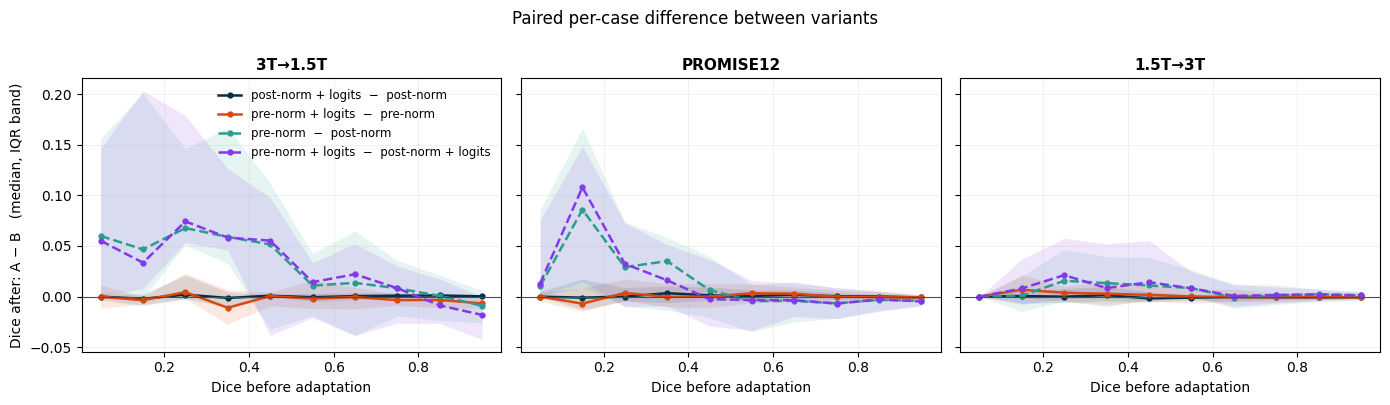

mean  median  A better %  B better %    p01    p99  ρ(ΔA, ΔB)
A − B                                    domain                                                                   
post-norm + logits  −  post-norm         3T→1.5T    0.000   0.000      42.412      25.988 -0.044  0.043      0.987
                                         PROMISE12  0.001   0.000      42.308      37.340 -0.031  0.042      0.990
                                         1.5T→3T   -0.000   0.000      25.870      36.218 -0.029  0.028      0.823
pre-norm + logits  −  pre-norm           3T→1.5T   -0.004  -0.003      31.601      59.459 -0.075  0.057      0.978
                                         PROMISE12  0.000   0.000      44.631      42.949 -0.055  0.046      0.978
                                         1.5T→3T    0.001   0.000      36.307      34.612 -0.028  0.051      0.843
pre-norm  −  post-norm                   3T→1.5T    0.017   0.004      53.638      41.580 -0.110  0.344      0.826
                                         PROMISE12  0.005  -0.002      43.429      51.122 -0.128  0.235      0.866
                                         1.5T→3T    0.006   0.000      46.387      32.649 -0.042  0.148      0.414
pre-norm + logits  −  post-norm + logits 3T→1.5T    0.013   0.000      49.272      46.362 -0.121  0.348      0.816
                                         PROMISE12  0.004  -0.002      42.869      51.122 -0.121  0.219      0.882
                                         1.5T→3T    0.008   0.000      47.814      30.598 -0.036  0.173      0.390

In [16]:
CONTRASTS = [  # (A, B) -> A − B
    ("post-norm + logits", "post-norm"),
    ("pre-norm + logits", "pre-norm"),
    ("pre-norm", "post-norm"),
    ("pre-norm + logits", "post-norm + logits"),
]
CONTRAST_STYLE = ["-", "-", "--", "--"]
CONTRAST_COLOUR = ["#023047", "#d9480f", "#2a9d8f", "#8338ec"]


def paired_cases(frame, domain, a, b):
    """(dice_after A, dice_after B, dice_before) per case, each averaged over predictors."""
    sub = frame[frame.domain == domain]
    per_case = sub.groupby(["run", "case"], observed=True)[["dice_after", "dice_before"]].mean()
    A, B = per_case.loc[a], per_case.loc[b]
    return A.dice_after.values, B.dice_after.values, A.dice_before.values


def available_contrasts(frame):
    present = set(frame.run.unique())
    return [(i, a, b) for i, (a, b) in enumerate(CONTRASTS) if a in present and b in present]


def head_to_head(frame, eps=EPS):
    rows = []
    for _, a, b in available_contrasts(frame):
        for domain in ORDER:
            A, B, base = paired_cases(frame, domain, a, b)
            d = A - B
            rows.append({"A − B": f"{a}  −  {b}", "domain": domain,
                         "mean": d.mean(), "median": np.median(d),
                         "A better %": 100 * (d > eps).mean(), "B better %": 100 * (d < -eps).mean(),
                         "p01": np.percentile(d, 1), "p99": np.percentile(d, 99),
                         "ρ(ΔA, ΔB)": spearmanr(A - base, B - base).statistic})
    return pd.DataFrame(rows).set_index(["A − B", "domain"])


def plot_head_to_head(frame):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
    for ax, domain in zip(axes, ORDER):
        for i, a, b in available_contrasts(frame):
            A, B, base = paired_cases(frame, domain, a, b)
            grouped = pd.Series(A - B).groupby(pd.cut(base, BINS, include_lowest=True), observed=False)
            ax.fill_between(BIN_CENTRES, grouped.quantile(0.25), grouped.quantile(0.75),
                            color=CONTRAST_COLOUR[i], alpha=0.12, lw=0)
            ax.plot(BIN_CENTRES, grouped.median(), "o", ls=CONTRAST_STYLE[i], color=CONTRAST_COLOUR[i],
                    ms=3.5, lw=1.8, label=f"{a}  −  {b}")
        ax.axhline(0, color="0.3", lw=0.8)
        ax.set_title(domain, fontsize=11, fontweight="bold")
        ax.set_xlabel("Dice before adaptation")
        ax.grid(alpha=0.25, lw=0.5)
    axes[0].set_ylabel("Dice after: A − B   (median, IQR band)")
    axes[0].legend(frameon=False, fontsize=8.5)
    fig.suptitle("Paired per-case difference between variants", fontsize=12, y=1.0)
    fig.tight_layout()
    return fig


plot_head_to_head(dfv)
plt.show()

head_to_head(dfv).round(3)

## 7.4 · Predictor agreement and μ̂ calibration, per variant

Agreement as in section 4, without the rerun ceiling (there are no repeated 100-step runs of these
checkpoints). Calibration as in section 6, once per predictor family — `mu_before` is computed
before any adaptation, so the logit adapter does not enter it.

In [17]:
display(pd.concat([predictor_agreement(v, ceiling_run=None) for v in VARIANTS],
                  ignore_index=True).round(3))

families = {}
for v in VARIANTS:
    families.setdefault(f"{RUNS[v].hook}-norm predictor", v)
pd.concat({family: calibration(v) for family, v in families.items()}, names=["predictor"]).round(3)

,domain,run,ρ across predictors,ρ min,ρ max
0,3T→1.5T,post-norm,0.678,0.490,0.770
1,PROMISE12,post-norm,0.757,0.715,0.816
2,1.5T→3T,post-norm,0.320,0.227,0.407
3,3T→1.5T,post-norm + logits,0.696,0.538,0.788
4,PROMISE12,post-norm + logits,0.774,0.724,0.820
5,1.5T→3T,post-norm + logits,0.310,0.144,0.452
6,3T→1.5T,pre-norm,0.731,0.655,0.777
7,PROMISE12,pre-norm,0.648,0.565,0.715
8,1.5T→3T,pre-norm,0.344,0.285,0.410
9,3T→1.5T,pre-norm + logits,0.713,0.677,0.751


n   Dice     μ̂   Bias  Pearson  Spearman
predictor           domain    split                                              
post-norm predictor 3T→1.5T   val     103  0.860  0.872  0.011    0.549     0.710
                              test    481  0.677  0.681  0.004    0.904     0.839
                    PROMISE12 val      64  0.862  0.891  0.030    0.770     0.814
                              test   1248  0.642  0.665  0.023    0.856     0.820
                    1.5T→3T   val      49  0.867  0.930  0.063    0.313     0.607
                              test   1121  0.526  0.797  0.271    0.687     0.777
pre-norm predictor  3T→1.5T   val     103  0.860  0.866  0.005    0.544     0.701
                              test    481  0.677  0.674 -0.003    0.921     0.846
                    PROMISE12 val      64  0.862  0.895  0.033    0.771     0.804
                              test   1248  0.642  0.632 -0.010    0.855     0.817
                    1.5T→3T   val      49  0.867  0.925  0.058    0.390     0.749
                              test   1121  0.526  0.732  0.206    0.672     0.713

## 7.5 · Selective adaptation, per variant

The gate from section 6, with `t*` taken from each variant's own mean trajectory (7.2) instead
of the 1000-step runs. Table: adapt everything vs. only the lowest 30 % μ̂; then the retention knee
and the risk–coverage curves for every variant.

adapt %   Dice      Δ  harmed %  broke <0.5 %  Δ | adaptiert  harmed % | adaptiert
run                domain    t*  gate                                                                                                
post-norm          3T→1.5T   100 alle              100.000  0.736  0.058    23.992         0.541          0.058                23.992
                                 unterste 30 % μ̂   30.021  0.726  0.048     2.121         0.083          0.161                 7.064
                   PROMISE12 100 alle              100.000  0.697  0.055    20.994         0.176          0.055                20.994
                                 unterste 30 % μ̂   30.000  0.677  0.035     2.788         0.080          0.118                 9.295
                   1.5T→3T   100 alle              100.000  0.532  0.006    31.258         0.268          0.006                31.258
                                 unterste 30 % μ̂   30.009  0.530  0.004     8.011         0.161          0.013                26.694
post-norm + logits 3T→1.5T   100 alle              100.000  0.736  0.059    23.077         0.624          0.059                23.077
                                 unterste 30 % μ̂   30.021  0.726  0.048     1.996         0.083          0.161                 6.648
                   PROMISE12 100 alle              100.000  0.698  0.056    21.138         0.192          0.056                21.138
                                 unterste 30 % μ̂   30.000  0.678  0.036     2.436         0.080          0.120                 8.120
                   1.5T→3T   96  alle              100.000  0.531  0.006    33.327         0.357          0.006                33.327
                                 unterste 30 % μ̂   30.009  0.529  0.004     8.296         0.161          0.013                27.646
pre-norm           3T→1.5T   59  alle              100.000  0.760  0.082    25.156         1.123          0.082                25.156
                                 unterste 30 % μ̂   30.021  0.746  0.069     2.121         0.333          0.228                 7.064
                   PROMISE12 80  alle              100.000  0.702  0.060    25.881         0.272          0.060                25.881
                                 unterste 30 % μ̂   30.000  0.684  0.042     3.173         0.080          0.140                10.577
                   1.5T→3T   100 alle              100.000  0.538  0.013    28.635         0.339          0.013                28.635
                                 unterste 30 % μ̂   30.009  0.535  0.009     6.530         0.107          0.031                21.760
pre-norm + logits  3T→1.5T   56  alle              100.000  0.759  0.082    25.904         1.164          0.082                25.904
                                 unterste 30 % μ̂   30.021  0.746  0.069     1.954         0.291          0.228                 6.510
                   PROMISE12 85  alle              100.000  0.702  0.060    26.058         0.353          0.060                26.058
                                 unterste 30 % μ̂   30.000  0.684  0.042     3.109         0.160          0.140                10.363
                   1.5T→3T   100 alle              100.000  0.540  0.014    29.081         0.250          0.014                29.081
                                 unterste 30 % μ̂   30.009  0.536  0.010     6.120         0.089          0.035                20.392

Knie-Coverage  Gewinn behalten  Schaden behalten  Gewinn @ 30%  Schaden @ 30%
run                domain                                                                                 
post-norm          3T→1.5T             25%            0.730             0.106         0.782          0.180
                   PROMISE12           45%            0.773             0.306         0.608          0.199
                   1.5T→3T             15%            0.379             0.207         0.548          0.457
post-norm + logits 3T→1.5T             25%            0.723             0.096         0.775          0.169
                   PROMISE12           45%            0.771             0.281         0.607          0.172
                   1.5T→3T             15%            0.388             0.221         0.560          0.454
pre-norm           3T→1.5T             25%            0.706             0.050         0.759          0.146
                   PROMISE12           35%            0.702             0.210         0.641          0.156
                   1.5T→3T             25%            0.569             0.330         0.641          0.408
pre-norm + logits  3T→1.5T             25%            0.707             0.050         0.760          0.125
                   PROMISE12           35%            0.690             0.209         0.631          0.154
                   1.5T→3T             30%            0.650             0.399         0.650          0.399

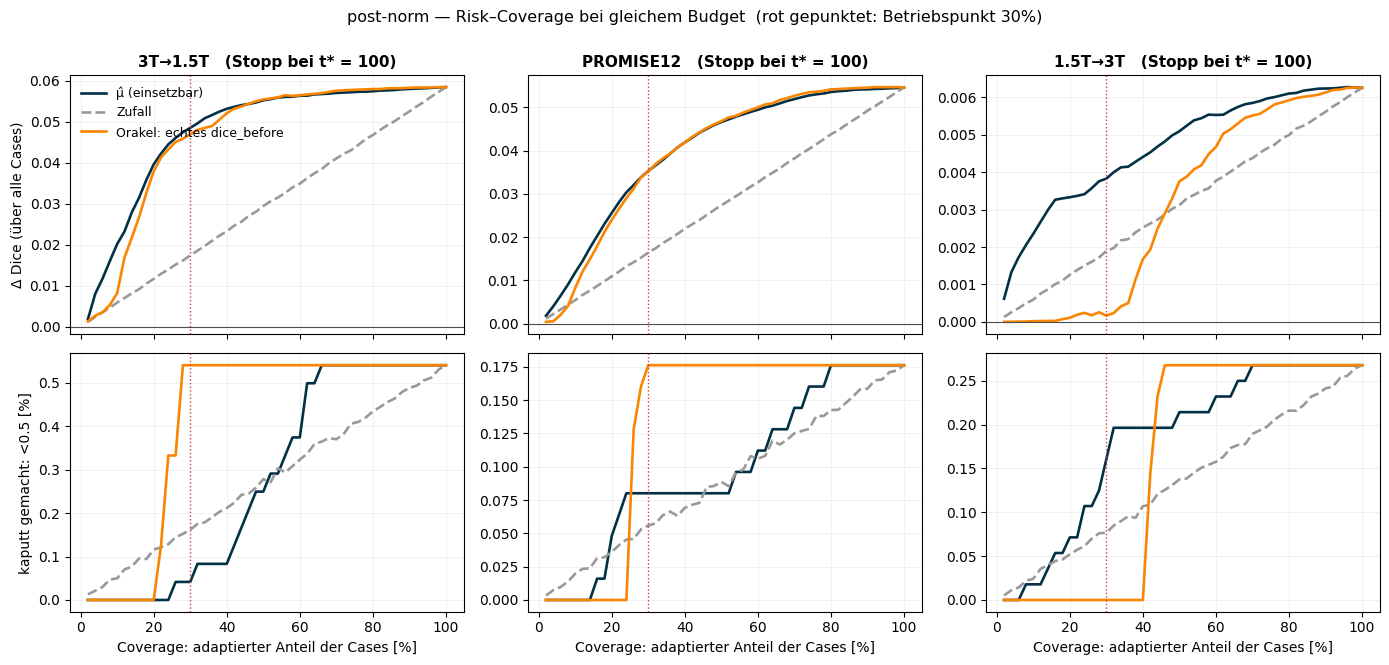

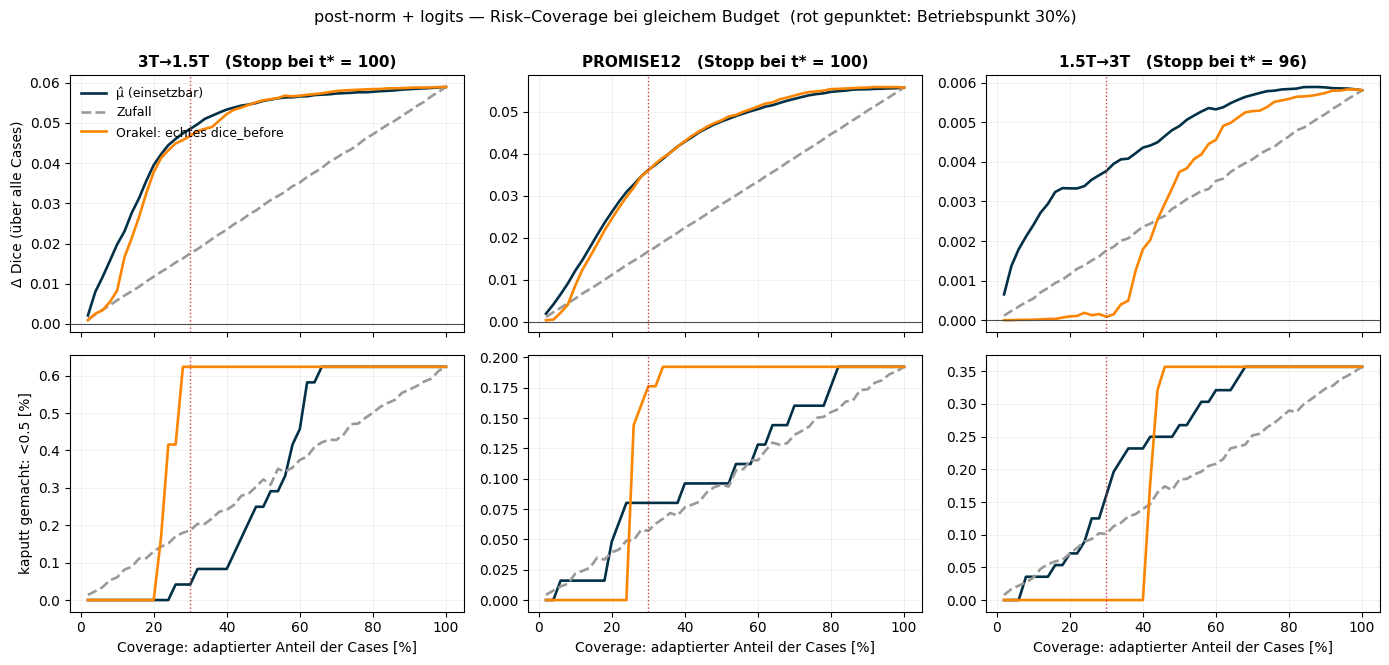

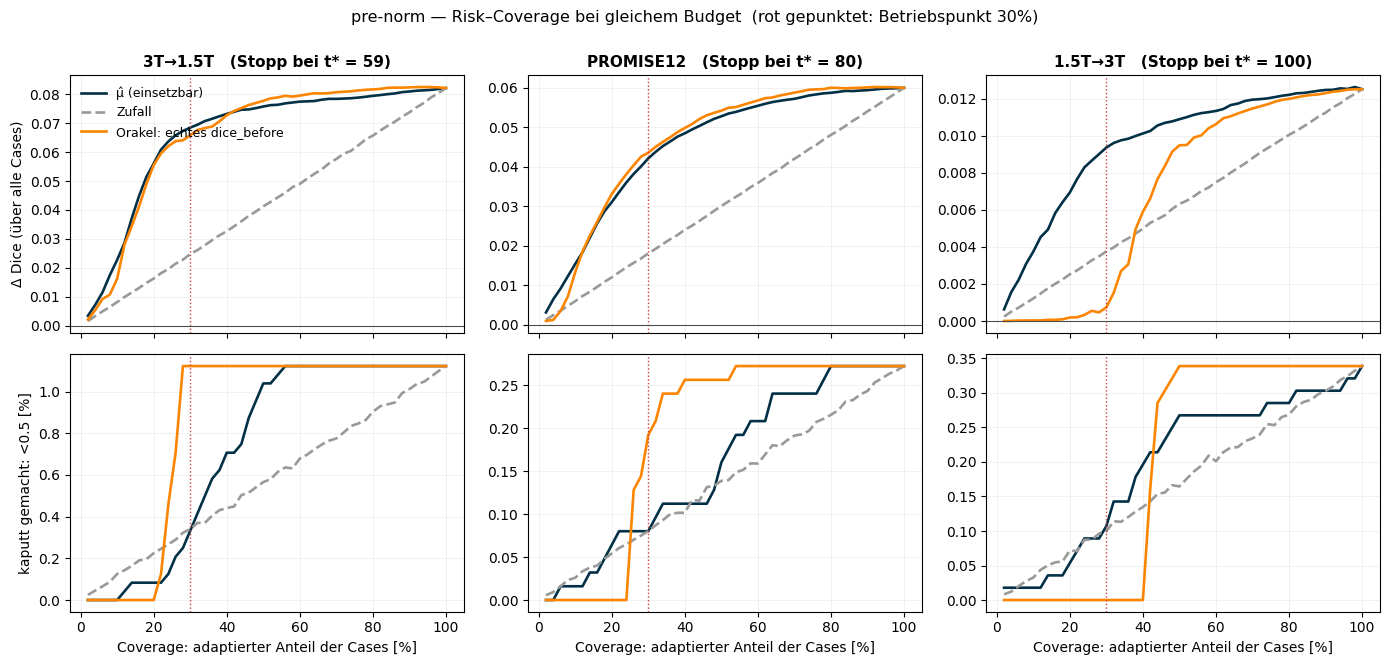

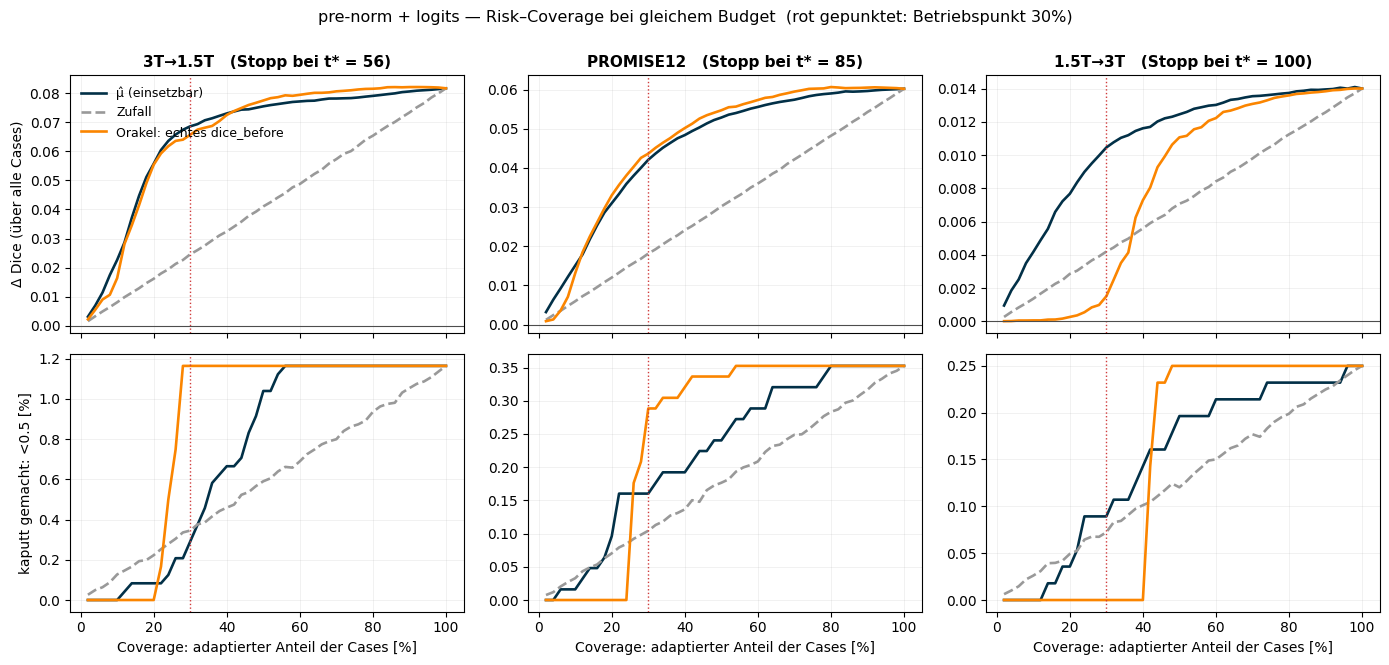

In [18]:
T_STAR_V = {
    v: {d: int(np.concatenate([curve(d, v, p) for p in PREDICTORS]).mean(0).argmax()) for d in DOMAINS}
    for v in VARIANTS
}

gates = pd.concat({v: gate_table(v, T_STAR_V[v]) for v in VARIANTS}, names=["run"])
display(gates[gates.index.get_level_values("gate").isin(["alle", f"unterste {int(COVERAGE*100)} % μ̂"])]
        .round(3))

display(pd.concat({v: knee_table(v, T_STAR_V[v]) for v in VARIANTS}, names=["run"]).round(3))

for v in VARIANTS:
    plot_risk_coverage(step_of=T_STAR_V[v].get, run=v)
    plt.show()

## 7.6 · Verbessert / verschlechtert im Verlauf, aufgeschlüsselt nach Baseline-Dice

Abschnitt 5 zeigt den Anteil verbesserter und verschlechterter Cases über die Schritte, Abschnitt
2 zeigt Δ Dice nach Baseline-Dice. Hier beides zusammen: pro Bin des Ausgangs-Dice der Anteil der
Cases, die zum Schritt *t* mehr als `TOL` über (durchgezogen) bzw. unter (gestrichelt) ihrem
Startwert liegen. Gepoolt über die 5 Predictors.

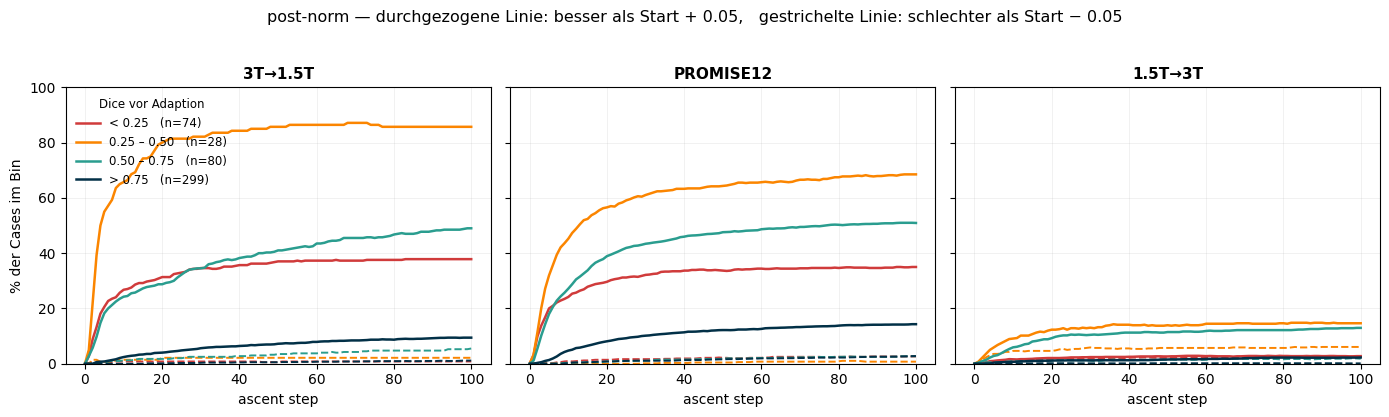

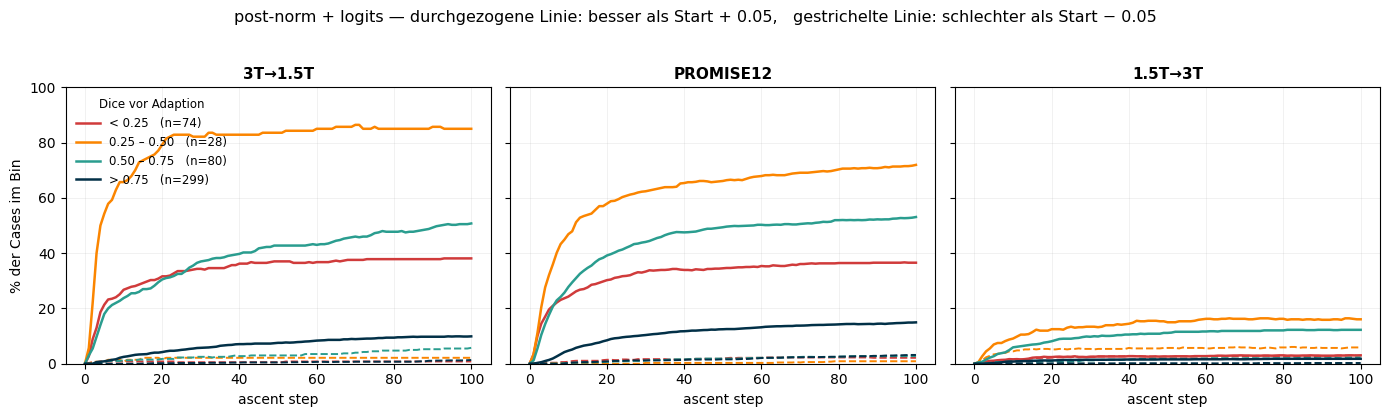

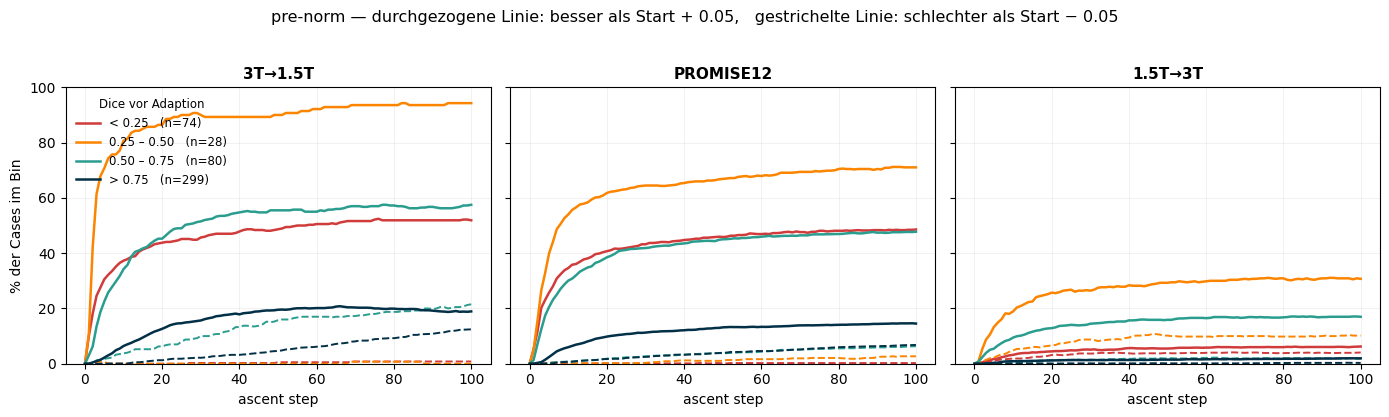

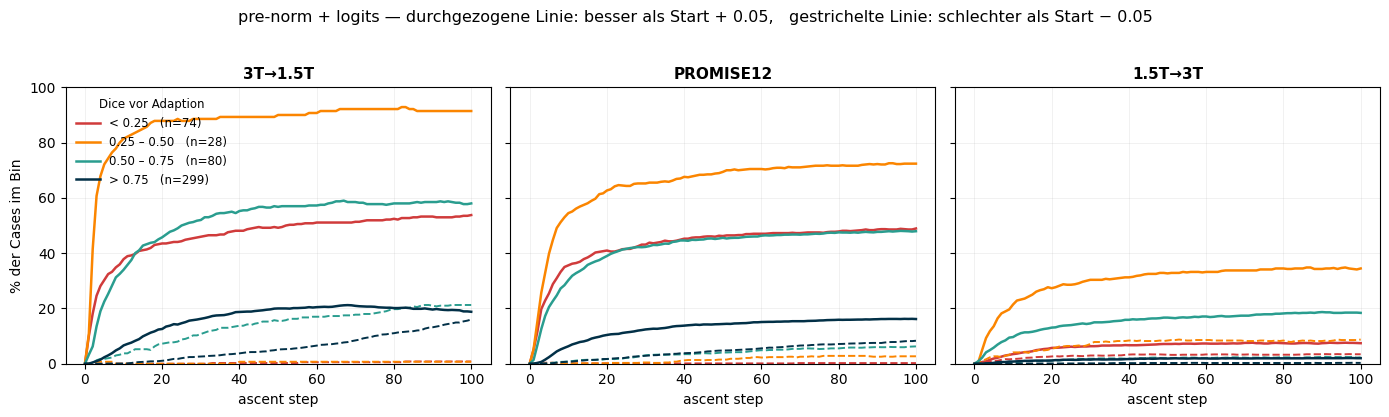

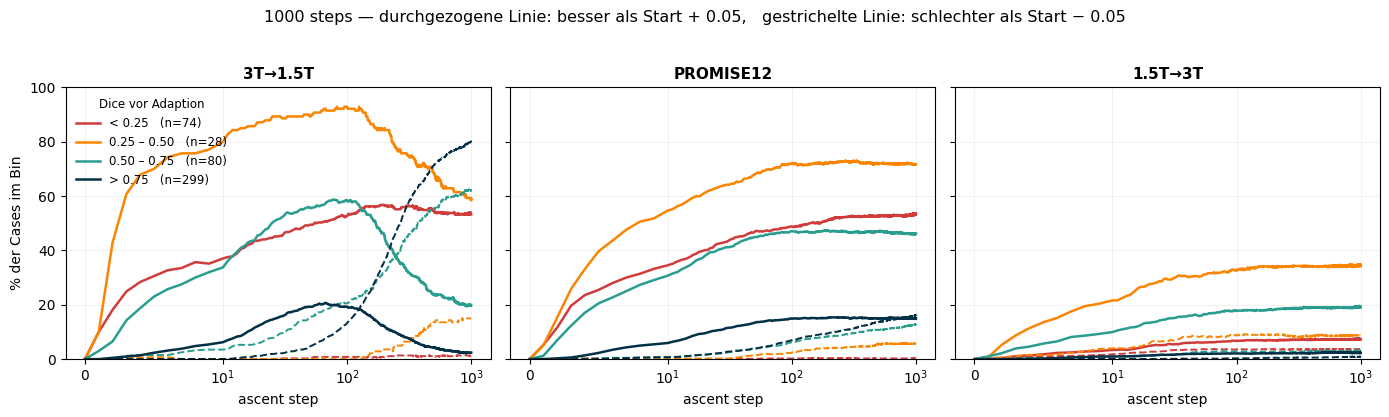

In [19]:
BASE_BINS = [(0.0, 0.25), (0.25, 0.50), (0.50, 0.75), (0.75, 1.01)]
BASE_LABEL = ["< 0.25", "0.25 – 0.50", "0.50 – 0.75", "> 0.75"]
BASE_COLOUR = ["#d03b3b", "#fb8500", "#2a9d8f", "#023047"]


def baseline_bin_masks(start):
    return [(start >= lo) & (start < hi) for lo, hi in BASE_BINS]


def plot_helped_harmed_by_baseline(run, tol=TOL):
    """Share improved / degraded over the ascent, one line per baseline-Dice bin."""
    name = resolve(run)
    steps = np.arange(RUNS[name].steps + 1)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
    for ax, (domain, label) in zip(axes, DOMAINS.items()):
        C = np.concatenate([curve(domain, name, p) for p in PREDICTORS])
        start = C[:, 0]
        for m, lab, col in zip(baseline_bin_masks(start), BASE_LABEL, BASE_COLOUR):
            if not m.any():
                continue
            base = C[m][:, [0]]
            ax.plot(steps, (C[m] > base + tol).mean(0) * 100, "-", color=col, lw=1.8,
                    label=f"{lab}   (n={m.sum() // len(PREDICTORS)})")
            ax.plot(steps, (C[m] < base - tol).mean(0) * 100, "--", color=col, lw=1.4)
        if RUNS[name].steps > 200:
            ax.set_xscale("symlog", linthresh=10)
        ax.set_title(label, fontsize=11, fontweight="bold")
        ax.set_xlabel("ascent step")
        ax.set_ylim(0, 100)
        ax.grid(alpha=0.25, lw=0.5)
    axes[0].set_ylabel(f"% der Cases im Bin")
    axes[0].legend(frameon=False, fontsize=8.5, title="Dice vor Adaption", title_fontsize=8.5)
    fig.suptitle(f"{name} — durchgezogene Linie: besser als Start + {tol},   "
                 f"gestrichelte Linie: schlechter als Start − {tol}", fontsize=11.5, y=1.03)
    fig.tight_layout()
    return fig


for v in VARIANTS:
    plot_helped_harmed_by_baseline(v)
    plt.show()

plot_helped_harmed_by_baseline(1000)   # Vergleich: das Budget aus Abschnitt 5
plt.show()

In [20]:
def helped_harmed_table(runs, tol=TOL):
    """Stand am Ende des Budgets, je Baseline-Bin."""
    rows = []
    for run in runs:
        name = resolve(run)
        for domain, label in DOMAINS.items():
            C = np.concatenate([curve(domain, name, p) for p in PREDICTORS])
            start, final = C[:, 0], C[:, -1]
            peak = C.max(1)
            for m, lab in zip(baseline_bin_masks(start), BASE_LABEL):
                if not m.any():
                    continue
                d = final[m] - start[m]
                rows.append({
                    "run": name, "domain": label, "Dice₀": lab,
                    "n": m.sum() // len(PREDICTORS),
                    "mean Δ": d.mean(), "median Δ": np.median(d),
                    "besser %": 100 * (d > tol).mean(),
                    "schlechter %": 100 * (d < -tol).mean(),
                    "netto %": 100 * ((d > tol).mean() - (d < -tol).mean()),
                    "Δ Orakel": (peak[m] - start[m]).mean(),
                })
    out = pd.DataFrame(rows)
    out["domain"] = pd.Categorical(out.domain, ORDER, ordered=True)
    out["Dice₀"] = pd.Categorical(out["Dice₀"], BASE_LABEL, ordered=True)
    return out.sort_values(["run", "domain", "Dice₀"], kind="stable").set_index(["run", "domain", "Dice₀"])


print(helped_harmed_table(VARIANTS + [20, 100, 1000]).round(3))

                                           n  mean Δ  median Δ  besser %  schlechter %  netto %  Δ Orakel
run               domain    Dice₀                                                                        
100 steps         3T→1.5T   < 0.25        74   0.271     0.077    52.162         1.081   51.081     0.288
                            0.25 – 0.50   28   0.321     0.353    93.571         0.000   93.571     0.348
                            0.50 – 0.75   80   0.069     0.083    57.500        20.750   36.750     0.112
                            > 0.75       299   0.006     0.009    18.863        13.110    5.753     0.036
                  PROMISE12 < 0.25       168   0.163     0.045    48.690         0.238   48.452     0.170
...                                      ...     ...       ...       ...           ...      ...       ...
pre-norm + logits PROMISE12 > 0.75       611   0.010     0.008    16.170         8.314    7.856     0.027
                  1.5T→3T   < 0.25       350  

## 7.7 · Dieselben Kurven, aber je Predictor-Familie zusammengefasst

Abschnitt 7.6 zeigt eine Figur pro Variante, der Vergleich mit/ohne Logit-Affine muss also
zwischen zwei Figuren gemacht werden. Hier stattdessen **eine Figur pro Norm-Variante des
Predictors**, in der beide Logit-Einstellungen übereinander liegen:

* **obere Zeile** verbesserte Cases (`Dice(t) > Dice(0) + TOL`), **untere Zeile** verschlechterte
  (`Dice(t) < Dice(0) − TOL`) -- dadurch wird der Linienstil frei für die Logits,
* **Farbe** = Bin des Ausgangs-Dice, wie in 7.6,
* **durchgezogen** = ohne Logit-Affine, **gepunktet** = mit.

Die beiden Zeilen haben **unterschiedliche y-Skalen** (`sharey="row"`), weil der Schaden sonst
platt am Boden liegt. Zwischen den Zeilen also nicht die Höhe vergleichen, sondern die Zahlen.

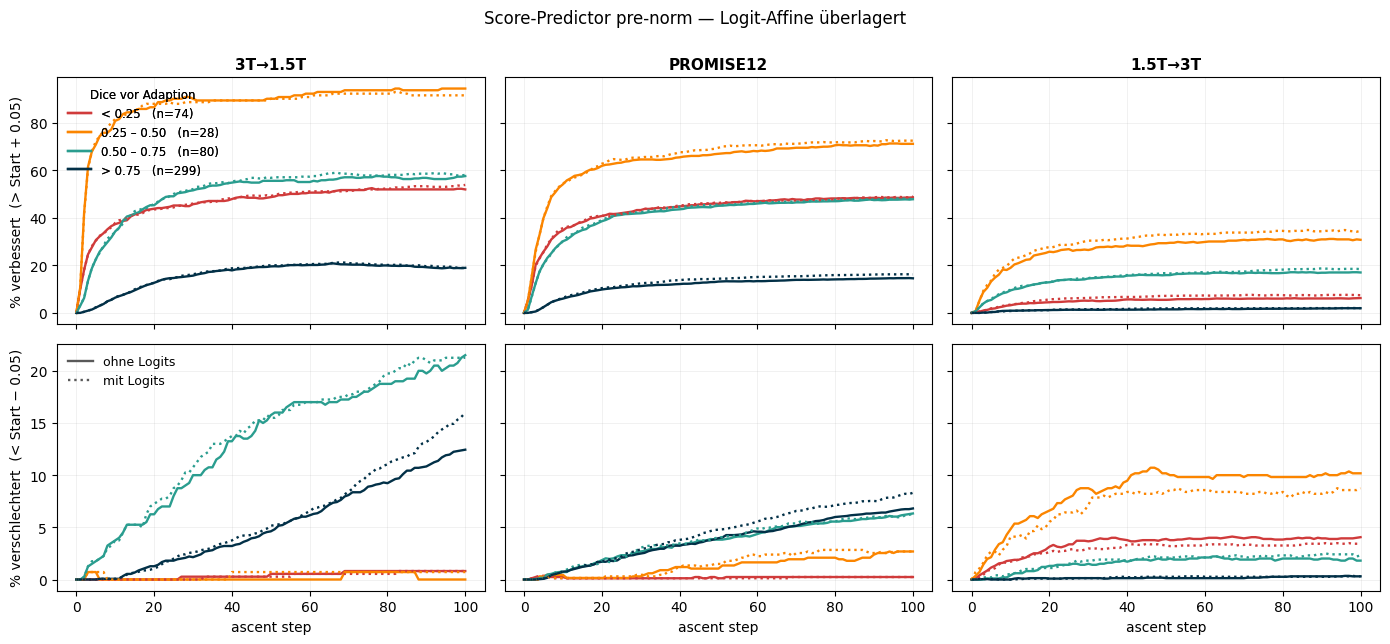

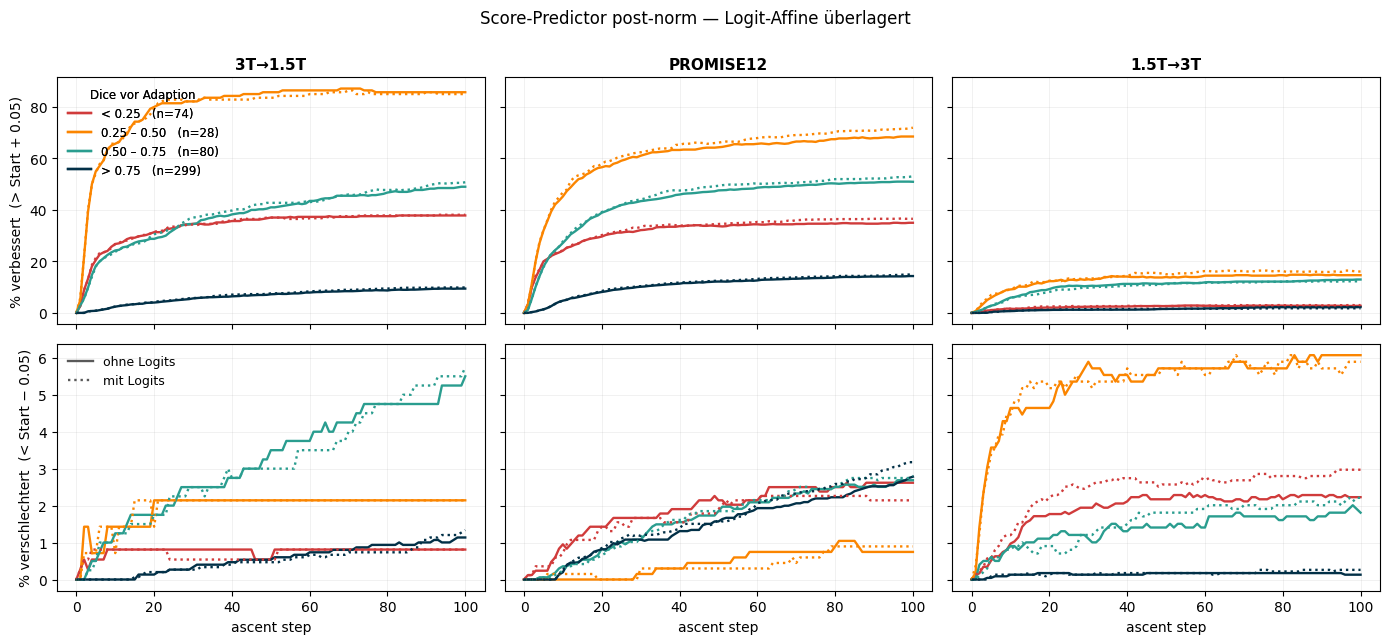

In [21]:
LOGIT_STYLE = {False: "-", True: ":"}


def plot_by_norm(hook, tol=TOL):
    """One figure per predictor family: improved (top) / degraded (bottom) x domain,
    with and without the logit affine in the same panel."""
    runs = [v for v in VARIANTS if RUNS[v].hook == hook]
    if not runs:
        print(f"keine Variante mit hook_placement={hook!r} geladen")
        return None
    fig, axes = plt.subplots(2, 3, figsize=(14, 6.4), sharex=True, sharey="row")
    for j, (domain, label) in enumerate(DOMAINS.items()):
        for run in runs:
            style = LOGIT_STYLE[bool(RUNS[run].logits)]
            C = np.concatenate([curve(domain, run, p) for p in PREDICTORS])
            steps = np.arange(C.shape[1])
            start = C[:, 0]
            for m, lab, col in zip(baseline_bin_masks(start), BASE_LABEL, BASE_COLOUR):
                if not m.any():
                    continue
                base = C[m][:, [0]]
                axes[0, j].plot(steps, (C[m] > base + tol).mean(0) * 100, style,
                                color=col, lw=1.7,
                                label=f"{lab}   (n={m.sum() // len(PREDICTORS)})"
                                      if not RUNS[run].logits else None)
                axes[1, j].plot(steps, (C[m] < base - tol).mean(0) * 100, style,
                                color=col, lw=1.7)
        axes[0, j].set_title(label, fontsize=11, fontweight="bold")
        axes[1, j].set_xlabel("ascent step")
        for ax in (axes[0, j], axes[1, j]):
            ax.grid(alpha=0.25, lw=0.5)
    axes[0, 0].set_ylabel(f"% verbessert  (> Start + {tol})")
    axes[1, 0].set_ylabel(f"% verschlechtert  (< Start − {tol})")
    bins_legend = axes[0, 0].legend(frameon=False, fontsize=8.5, title="Dice vor Adaption",
                                    title_fontsize=8.5, loc="upper left")
    axes[0, 0].add_artist(bins_legend)
    axes[1, 0].legend(handles=[Line2D([], [], color="0.35", ls=LOGIT_STYLE[False], lw=1.7,
                                      label="ohne Logits"),
                               Line2D([], [], color="0.35", ls=LOGIT_STYLE[True], lw=1.7,
                                      label="mit Logits")],
                      frameon=False, fontsize=9, loc="upper left")
    fig.suptitle(f"Score-Predictor {hook}-norm — Logit-Affine überlagert", fontsize=12, y=1.0)
    fig.tight_layout()
    return fig


for hook in ("pre", "post"):
    if plot_by_norm(hook) is not None:
        plt.show()